# BraTS 2024 — Client 2 DeepLabV3+ Training Pipeline
**Hospital B | Slice-Based Segmentation | Federated Learning Client 2**

- Model: DeepLabV3+ with ResNet-50 backbone (4-channel MRI input)
- Input: 2D slices (B, 4, 128, 128) from 3D MRI volumes
- ASPP: Atrous Spatial Pyramid Pooling with dilation rates 1, 6, 12, 18
- Feature extraction: 16 evenly-spaced slices stacked → (B, 256, 16, 16, 16)
- Dataset: BraTS-GLI 2024 — Hospital B (independent from Client 1)
- Hardware: Google Colab Free Tier (T4 GPU, ~15 GB VRAM)


## Cell 1 — Install Dependencies

In [ ]:
!pip install nibabel -q
!pip install scikit-learn -q
!pip install tqdm -q
!pip install torchinfo -q
!pip install segmentation-models-pytorch -q
!pip install torchmetrics
!pip install surface_distance # Added missing dependency

print("✓ All dependencies installed")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 25.9 MB/s eta 0:00:00
✓ All dependencies installed


## Cell 2 — Mount Google Drive
Mounts Drive so checkpoints and preprocessed data persist across sessions.
All Client 2 data, checkpoints and extracted features are saved under
`MyDrive/BraTS2024_DeepLabV3/`.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_BASE = '/content/drive/MyDrive/BraTS2024_DeepLabV3'
os.makedirs(DRIVE_BASE, exist_ok=True)
print(f"✓ Drive mounted. Base path: {DRIVE_BASE}")


Mounted at /content/drive
✓ Drive mounted. Base path: /content/drive/MyDrive/BraTS2024_DeepLabV3


## Cell 3 — Imports
All imports in one place. Sets PYTORCH_ALLOC_CONF before torch import
to prevent CUDA memory fragmentation on T4.


In [ ]:
import os
os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"

import gc
import json
import random
import shutil
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from dataclasses import dataclass
from pathlib import Path
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.tensorboard import SummaryWriter

import segmentation_models_pytorch as smp
from torchmetrics import MeanMetric
from torchmetrics.classification import MulticlassAccuracy

# New imports from user's snippet
from sklearn.preprocessing import MinMaxScaler
import surface_distance as sd

print(f"PyTorch  : {torch.__version__}")
print(f"CUDA     : {torch.version.cuda}")
print(f"GPU      : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

PyTorch  : 2.10.0+cu128
CUDA     : 12.8
GPU      : Tesla T4


## Cell 4 — Configuration
Central config for all hyperparameters and paths.
BATCH_SIZE=4 slices per step — 2D slices are much lighter than 3D volumes.


In [ ]:
@dataclass(frozen=True)
class Config:
    # ── Data paths ──────────────────────────────────────────────────────────
    DATASET_PATH:      str   = "/content/drive/MyDrive/client B dataset/Client_2_Hospital_B"
    PREPROCESSED_PATH: str   = "BraTS2024_Client2_Preprocessed"
    DRIVE_BASE:        str   = "/content/drive/MyDrive/BraTS2024_DeepLabV3"

    # ── Sampling ─────────────────────────────────────────────────────────────
    NUM_FILES_TO_USE:  int   = 500
    RANDOM_SEED:       int   = 42
    TRAIN_RATIO:       float = 0.75

    # ── ROI crop — same as Client 1 for consistency ──────────────────────────
    CROP_X:            tuple = (56, 184)
    CROP_Y:            tuple = (56, 184)
    CROP_Z:            tuple = (13, 141)

    # ── Training ─────────────────────────────────────────────────────────────
    BATCH_SIZE:        int   = 4
    EPOCHS:            int   = 50
    LEARNING_RATE:     float = 1e-4
    WEIGHT_DECAY:      float = 1e-2
    NUM_WORKERS:       int   = 2
    PIN_MEMORY:        bool  = True
    AMP_ENABLED:       bool  = True
    GRAD_ACCUM_STEPS:  int   = 4

    # ── Model ────────────────────────────────────────────────────────────────
    IN_CHANNELS:       int   = 4
    OUT_CHANNELS:      int   = 4
    NUM_CLASSES:       int   = 4
    IMG_SIZE:          int   = 128

    # ── Slice-stacking for feature extraction ────────────────────────────────
    NUM_SLICES:        int   = 16

    # ── Checkpoints ──────────────────────────────────────────────────────────
    CHECKPOINT_DIR:    str   = "model_checkpoint/DeepLabV3_BraTS2024"


CFG = Config()
print("✓ Config loaded")
print(f"  Dataset     : {CFG.DATASET_PATH}")
print(f"  Drive base  : {CFG.DRIVE_BASE}")
print(f"  Batch size  : {CFG.BATCH_SIZE} slices")
print(f"  Epochs      : {CFG.EPOCHS}")
print(f"  LR          : {CFG.LEARNING_RATE}")


✓ Config loaded
  Dataset     : /content/drive/MyDrive/client B dataset/Client_2_Hospital_B
  Drive base  : /content/drive/MyDrive/BraTS2024_DeepLabV3
  Batch size  : 4 slices
  Epochs      : 50
  LR          : 0.0001


## Cell 5 — Utilities

In [ ]:
def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def get_device():
    gpu = torch.cuda.is_available()
    device = torch.device('cuda' if gpu else 'cpu')
    print(f"Using: {device}")
    return device, gpu


def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()


def create_checkpoint_dir(base_dir: str) -> str:
    os.makedirs(base_dir, exist_ok=True)
    try:
        versions = [int(d.split("_")[-1])
                    for d in os.listdir(base_dir) if "version" in d]
        v = max(versions) + 1
    except (ValueError, FileNotFoundError):
        v = 0
    vdir = os.path.join(base_dir, f"version_{v}")
    os.makedirs(vdir, exist_ok=True)
    print(f"Checkpoint dir: {vdir}")
    return vdir


seed_everything(CFG.RANDOM_SEED)
DEVICE, GPU_AVAILABLE = get_device()


Using: cuda


## Cell 6 — Collect Valid Cases
Scans the Hospital B dataset folder and returns only patient IDs
that have all 5 required files (t1n, t1ce, t2f, t2w, seg).


In [ ]:
def collect_all_cases(root) -> list:
    """Returns list of patient folder names that have all required files.
    Checks for both .nii.gz and .nii extensions for each modality.
    """
    valid = []
    if not os.path.exists(root):
        print(f"⚠ Dataset path not found: {root}")
        return valid

    for pid in sorted(os.listdir(root)):
        p = os.path.join(root, pid)
        if not os.path.isdir(p):
            continue
        files = os.listdir(p)
        req   = ["t1c", "t1n", "t2f", "t2w", "seg"]
        if all(any(k in f.lower() and (f.endswith(".nii") or f.endswith(".nii.gz")) for f in files) for k in req):
            valid.append(pid)
    return valid

def sample_files(cases: list, n: int, seed: int) -> list:
    random.seed(seed)
    selected = random.sample(cases, min(n, len(cases)))
    print(f"✓ Selected {len(selected)} cases for training")
    return selected


## Cell 7 — Preprocessing
Same preprocessing pipeline as Client 1.
Preprocessing is done locally — raw data never leaves the hospital.


In [ ]:
def load_modality(folder_path: str, keyword: str) -> np.ndarray:
    """Load a single NIfTI modality (either .nii or .nii.gz) and return as numpy array.
    """
    files = [f for f in os.listdir(folder_path)
             if keyword in f.lower() and (f.endswith('.nii.gz') or f.endswith('.nii'))]
    if not files:
        raise FileNotFoundError(f"No file with '{keyword}' in {folder_path}")
    path = os.path.join(folder_path, files[0])
    return nib.load(path).get_fdata(dtype=np.float32)

def minmax_normalize(vol: np.ndarray) -> np.ndarray:
    brain_mask = vol > 0
    if brain_mask.sum() == 0:
        return vol
    vmin = vol[brain_mask].min()
    vmax = vol[brain_mask].max()
    if vmax == vmin:
        return np.zeros_like(vol)
    normalized = np.zeros_like(vol)
    normalized[brain_mask] = (vol[brain_mask] - vmin) / (vmax - vmin)
    return normalized

def preprocess_patient(folder_path: str, cx: tuple, cy: tuple, cz: tuple) -> tuple:
    """Preprocesses a single patient's MRI data, including cropping and remapping segmentation labels.
    """
    t1n = minmax_normalize(load_modality(folder_path, 't1n'))
    t1c = minmax_normalize(load_modality(folder_path, 't1c'))
    t2f = minmax_normalize(load_modality(folder_path, 't2f'))
    t2w = minmax_normalize(load_modality(folder_path, 't2w'))
    seg = load_modality(folder_path, 'seg').astype(np.int32)
    seg[seg == 4] = 3   # remap label 4 to 3

    # Crop
    t1n  = t1n[cx[0]:cx[1], cy[0]:cy[1], cz[0]:cz[1]]
    t1c  = t1c[cx[0]:cx[1], cy[0]:cy[1], cz[0]:cz[1]]
    t2f  = t2f[cx[0]:cx[1], cy[0]:cy[1], cz[0]:cz[1]]
    t2w  = t2w[cx[0]:cx[1], cy[0]:cy[1], cz[0]:cz[1]]
    seg  = seg[cx[0]:cx[1], cy[0]:cy[1], cz[0]:cz[1]]

    image = np.stack([t1n, t1c, t2f, t2w], axis=-1).astype(np.float32)  # (H,W,D,4)
    return image, seg


## Cell 8 — Train/Val Split

In [ ]:
def create_train_val_split(preprocessed_path: str,
                            train_ratio: float = 0.75,
                            seed: int = 42):
    img_dir  = os.path.join(preprocessed_path, "images")
    mask_dir = os.path.join(preprocessed_path, "masks")
    all_imgs = sorted(os.listdir(img_dir))

    random.seed(seed)
    random.shuffle(all_imgs)
    n_train = int(len(all_imgs) * train_ratio)
    train_imgs = all_imgs[:n_train]
    val_imgs   = all_imgs[n_train:]

    for split, files in [("train", train_imgs), ("val", val_imgs)]:
        for sub in ["images", "masks"]:
            os.makedirs(os.path.join(preprocessed_path, split, sub), exist_ok=True)
        for fname in files:
            shutil.copy2(
                os.path.join(img_dir,  fname),
                os.path.join(preprocessed_path, split, "images", fname)
            )
            shutil.copy2(
                os.path.join(mask_dir, fname),
                os.path.join(preprocessed_path, split, "masks", fname)
            )

    print(f"✓ Split: {len(train_imgs)} train | {len(val_imgs)} val")


## Cell 9 — Dataset (Slice-Based)
Client 2 uses 2D slices — each volume is stored as 128×128×128.
During training, one random axial slice is sampled per volume per step.


In [ ]:
SLICES_PER_VOLUME = 8

class BraTS2024SliceDataset(Dataset):
    def __init__(self, img_dir: str, mask_dir: str, augment: bool = False):
        super().__init__()
        self.img_dir   = img_dir
        self.mask_dir  = mask_dir
        self.img_list  = sorted(os.listdir(img_dir))
        self.mask_list = sorted(os.listdir(mask_dir))
        self.augment   = augment
        print(f"✓ Train dataset ready — {len(self.img_list)} volumes "
              f"× {SLICES_PER_VOLUME} slices = "
              f"{len(self.img_list) * SLICES_PER_VOLUME} total")

    def __len__(self):
        return len(self.img_list) * SLICES_PER_VOLUME

    def __getitem__(self, idx):
        vol_idx = idx % len(self.img_list)
        img  = np.load(os.path.join(self.img_dir,  self.img_list[vol_idx]))
        mask = np.load(os.path.join(self.mask_dir, self.mask_list[vol_idx]))

        img  = torch.from_numpy(img).permute(3, 2, 0, 1).float()
        mask = torch.from_numpy(mask).permute(3, 2, 0, 1).float()

        if img.shape[1:] != (128, 128, 128):
            img  = F.interpolate(img.unsqueeze(0),  size=(128,128,128),
                                 mode='trilinear', align_corners=False).squeeze(0)
            mask = F.interpolate(mask.unsqueeze(0), size=(128,128,128),
                                 mode='nearest').squeeze(0)

        z = random.randint(img.shape[1] // 6, img.shape[1] - img.shape[1] // 6)
        img_slice  = img[:,  z, :, :]
        mask_slice = mask[:, z, :, :]

        if self.augment and random.random() > 0.5:
            img_slice  = torch.flip(img_slice,  dims=[2])
            mask_slice = torch.flip(mask_slice, dims=[2])
        if self.augment and random.random() > 0.5:
            img_slice  = torch.flip(img_slice,  dims=[1])
            mask_slice = torch.flip(mask_slice, dims=[1])

        mean = img_slice.mean(dim=(1, 2), keepdim=True)
        std  = img_slice.std(dim=(1, 2),  keepdim=True).clamp(min=1e-6)
        img_slice = (img_slice - mean) / std

        del img, mask
        return img_slice, mask_slice


class BraTS2024SliceDatasetFixed(Dataset):
    def __init__(self, img_dir: str, mask_dir: str):
        super().__init__()
        img_list  = sorted(os.listdir(img_dir))
        mask_list = sorted(os.listdir(mask_dir))

        print("Extracting validation slices into cache...")
        self.img_slices  = []
        self.mask_slices = []

        for img_f, mask_f in zip(img_list, mask_list):
            img  = np.load(os.path.join(img_dir,  img_f))
            mask = np.load(os.path.join(mask_dir, mask_f))

            img  = torch.from_numpy(img).permute(3, 2, 0, 1).float()
            mask = torch.from_numpy(mask).permute(3, 2, 0, 1).float()

            if img.shape[1:] != (128, 128, 128):
                img  = F.interpolate(img.unsqueeze(0),  size=(128,128,128),
                                     mode='trilinear', align_corners=False).squeeze(0)
                mask = F.interpolate(mask.unsqueeze(0), size=(128,128,128),
                                     mode='nearest').squeeze(0)

            for z in range(32, 96, 16):
                img_s  = img[:,  z, :, :]
                mask_s = mask[:, z, :, :]
                mean = img_s.mean(dim=(1, 2), keepdim=True)
                std  = img_s.std(dim=(1, 2),  keepdim=True).clamp(min=1e-6)
                img_s = (img_s - mean) / std
                self.img_slices.append(img_s)
                self.mask_slices.append(mask_s)

            del img, mask

        print(f"✓ {len(self.img_slices)} validation slices cached "
              f"({len(self.img_slices) * 4 * 128 * 128 * 4 / 1e6:.0f} MB)")

    def __len__(self):
        return len(self.img_slices)

    def __getitem__(self, idx):
        return self.img_slices[idx], self.mask_slices[idx]


In [ ]:
def create_dataloaders(cfg, drive_preproc_path):
    """Creates and returns train and validation DataLoader instances."""
    train_ds = BraTS2024SliceDataset(
        os.path.join(drive_preproc_path, "train", "images"),
        os.path.join(drive_preproc_path, "train", "masks"),
        augment=True,
    )
    val_ds = BraTS2024SliceDatasetFixed(
        os.path.join(drive_preproc_path, "val", "images"),
        os.path.join(drive_preproc_path, "val", "masks"),
    )

    train_loader = DataLoader(train_ds, batch_size=cfg.BATCH_SIZE, shuffle=True,
        num_workers=cfg.NUM_WORKERS, pin_memory=cfg.PIN_MEMORY,
        prefetch_factor=2, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=cfg.BATCH_SIZE, shuffle=False,
        num_workers=cfg.NUM_WORKERS, pin_memory=cfg.PIN_MEMORY)

    imgs, msks = next(iter(train_loader))
    print(f"Image batch : {imgs.shape}")
    print(f"Mask  batch : {msks.shape}")

    return train_loader, val_loader

print("✓ `create_dataloaders` function defined.")

✓ `create_dataloaders` function defined.


## Cell 10 — DeepLabV3+ Architecture
ResNet-50 backbone with 4-channel input. ASPP dilation rates 1,6,12,18.


In [ ]:
class ASPPConv(nn.Module):
    def __init__(self, in_ch, out_ch, dilation):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=dilation, dilation=dilation, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.block(x)

class ASPPPooling(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_ch, out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        size = x.shape[-2:]
        return F.interpolate(self.block(x), size=size, mode='bilinear', align_corners=False)

class ASPP(nn.Module):
    def __init__(self, in_ch, out_ch=256):
        super().__init__()
        self.b0 = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
        self.b1 = ASPPConv(in_ch, out_ch, 6)
        self.b2 = ASPPConv(in_ch, out_ch, 12)
        self.b3 = ASPPConv(in_ch, out_ch, 18)
        self.b4 = ASPPPooling(in_ch, out_ch)
        self.project = nn.Sequential(
            nn.Conv2d(out_ch * 5, out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True), nn.Dropout2d(0.1),
        )
    def forward(self, x):
        return self.project(torch.cat([self.b0(x), self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1))

class DeepLabV3Plus(nn.Module):
    def __init__(self, in_channels=4, num_classes=4, pretrained=True):
        super().__init__()
        import torchvision.models as models
        backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None)
        old_conv = backbone.conv1
        new_conv = nn.Conv2d(in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False)
        with torch.no_grad():
            new_conv.weight[:, :3, :, :] = old_conv.weight
            new_conv.weight[:, 3:4, :, :] = old_conv.weight.mean(dim=1, keepdim=True)
        backbone.conv1 = new_conv
        self.layer0 = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4
        self._set_layer_dilation(self.layer3, stride=2, dilation=2)
        self._set_layer_dilation(self.layer4, stride=2, dilation=4)
        self.aspp = ASPP(in_ch=2048, out_ch=256)
        self.low_level_proj = nn.Sequential(
            nn.Conv2d(256, 48, 1, bias=False), nn.BatchNorm2d(48), nn.ReLU(inplace=True),
        )
        self.decoder = nn.Sequential(
            nn.Conv2d(304, 256, 3, padding=1, bias=False), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Dropout2d(0.1),
            nn.Conv2d(256, 256, 3, padding=1, bias=False), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
        )
        self.seg_head = nn.Conv2d(256, num_classes, 1)
        self.aux_head = nn.Sequential(
            nn.Conv2d(256, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 1, 1),
        )
        self._init_new_layers()

    def _set_layer_dilation(self, layer, stride, dilation):
        for block_idx, block in enumerate(layer):
            if hasattr(block, 'conv2'):
                block.conv2.stride   = (1, 1)
                block.conv2.padding  = (dilation, dilation)
                block.conv2.dilation = (dilation, dilation)
            if block_idx == 0 and block.downsample is not None:
                for m in block.downsample:
                    if isinstance(m, nn.Conv2d) and m.stride == (stride, stride):
                        m.stride = (1, 1)

    def _init_new_layers(self):
        for m in [self.aspp, self.low_level_proj, self.decoder, self.seg_head, self.aux_head]:
            for layer in m.modules():
                if isinstance(layer, nn.Conv2d):
                    nn.init.kaiming_normal_(layer.weight, mode='fan_out', nonlinearity='relu')
                elif isinstance(layer, nn.BatchNorm2d):
                    nn.init.ones_(layer.weight); nn.init.zeros_(layer.bias)

    def forward(self, x):
        input_size = x.shape[-2:]
        x0  = self.layer0(x)
        x1  = self.layer1(x0)
        x2  = self.layer2(x1)
        x3  = self.layer3(x2)
        x4  = self.layer4(x3)
        aspp_out = self.aspp(x4)
        low = self.low_level_proj(x1)
        aspp_up = F.interpolate(aspp_out, size=low.shape[-2:], mode='bilinear', align_corners=False)
        dec_in  = torch.cat([aspp_up, low], dim=1)
        dec_out = self.decoder(dec_in)
        dec_up  = F.interpolate(dec_out, size=input_size, mode='bilinear', align_corners=False)
        seg = self.seg_head(dec_up)
        aux = self.aux_head(dec_up)
        return seg, aux, aspp_out

def verify_model():
    print("Running DeepLabV3+ sanity check...")
    m = DeepLabV3Plus(in_channels=4, num_classes=4, pretrained=False).eval()
    x = torch.randn(2, 4, 128, 128)
    with torch.no_grad():
        seg, aux, aspp = m(x)
    assert seg.shape  == (2, 4, 128, 128)
    assert aux.shape  == (2, 1, 128, 128)
    assert aspp.shape == (2, 256, 16, 16)
    total = sum(p.numel() for p in m.parameters())
    print(f"  Input : {x.shape}")
    print(f"  Seg   : {seg.shape}  ✓")
    print(f"  Aux   : {aux.shape}  ✓")
    print(f"  ASPP  : {aspp.shape}  ✓  ← feature extraction point")
    print(f"  Params: {total:,}")
    del m, x, seg, aux, aspp
    free_memory()
    print("✓ Architecture verified.\n")

verify_model()


Running DeepLabV3+ sanity check...
  Input : torch.Size([2, 4, 128, 128])
  Seg   : torch.Size([2, 4, 128, 128])  ✓
  Aux   : torch.Size([2, 1, 128, 128])  ✓
  ASPP  : torch.Size([2, 256, 16, 16])  ✓  ← feature extraction point
  Params: 40,498,597
✓ Architecture verified.



## Cell 11 — Loss Functions
Dice + Focal + 0.3 × BCE (binary auxiliary head)


In [ ]:
_dice_loss  = smp.losses.DiceLoss(mode='multiclass', from_logits=True, smooth=1e-5, eps=1e-7)
_focal_loss = smp.losses.FocalLoss(mode='multiclass', alpha=0.25, gamma=2.0)
_bce_loss   = nn.BCEWithLogitsLoss()

def combined_loss(seg_out, aux_out, target_cls, target_binary):
    l_dice  = _dice_loss(seg_out, target_cls)
    l_focal = _focal_loss(seg_out, target_cls)
    l_bce   = _bce_loss(aux_out, target_binary.float())
    return l_dice + l_focal + 0.3 * l_bce


## Cell 12 — Training Loop

In [ ]:
def train_one_epoch(model, loader, optimizer, scaler_amp,
                    device, epoch, total_epochs,
                    accum_steps=4, amp_enabled=True):
    model.train()
    loss_rec = MeanMetric()
    iou_rec  = MeanMetric()
    acc_rec  = MulticlassAccuracy(num_classes=CFG.NUM_CLASSES, average='macro')

    optimizer.zero_grad()

    with tqdm(total=len(loader), ncols=115) as pbar:
        pbar.set_description(f"Train | {epoch}/{total_epochs}")

        for step, (data, target) in enumerate(loader):
            data   = data.to(device, non_blocking=True).float()
            target = target.to(device, non_blocking=True).float()

            target_cls    = target.argmax(dim=1)
            target_binary = (target_cls > 0).unsqueeze(1).float()

            with torch.amp.autocast('cuda', enabled=amp_enabled):
                seg_out, aux_out, _ = model(data)
                loss = combined_loss(seg_out, aux_out, target_cls, target_binary)
                loss = loss / accum_steps

            scaler_amp.scale(loss).backward()

            if (step + 1) % accum_steps == 0 or (step + 1) == len(loader):
                scaler_amp.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler_amp.step(optimizer)
                scaler_amp.update()
                optimizer.zero_grad()

            with torch.no_grad():
                pred = seg_out.argmax(dim=1)
                tp, fp, fn, tn = smp.metrics.get_stats(
                    pred, target_cls, mode='multiclass', num_classes=CFG.NUM_CLASSES
                )
                iou = smp.metrics.iou_score(tp, fp, fn, tn, reduction='macro')
                acc_rec.update(pred.cpu(), target_cls.cpu())
                loss_rec.update((loss * accum_steps).cpu(), data.shape[0])
                iou_rec.update(iou.cpu(), data.shape[0])

            pbar.update(1)
            pbar.set_postfix_str(f"Loss:{loss_rec.compute():.4f} IoU:{iou_rec.compute():.4f}")
            del data, target, seg_out, aux_out

    return (loss_rec.compute().item(), iou_rec.compute().item(), acc_rec.compute().item())


## Cell 13 — Validation Loop

In [ ]:
def validate(model, loader, device, epoch, total_epochs, amp_enabled=True):
    model.eval()
    loss_rec = MeanMetric()
    iou_rec  = MeanMetric()
    acc_rec  = MulticlassAccuracy(num_classes=CFG.NUM_CLASSES, average='macro')

    with tqdm(total=len(loader), ncols=115) as pbar:
        pbar.set_description(f"Valid | {epoch}/{total_epochs}")

        for data, target in loader:
            data   = data.to(device, non_blocking=True).float()
            target = target.to(device, non_blocking=True).float()

            target_cls    = target.argmax(dim=1)
            target_binary = (target_cls > 0).unsqueeze(1).float()

            with torch.no_grad(), torch.amp.autocast('cuda', enabled=amp_enabled):
                seg_out, aux_out, _ = model(data)
                loss = combined_loss(seg_out, aux_out, target_cls, target_binary)

            pred = seg_out.argmax(dim=1)
            tp, fp, fn, tn = smp.metrics.get_stats(
                pred, target_cls, mode='multiclass', num_classes=CFG.NUM_CLASSES
            )
            iou = smp.metrics.iou_score(tp, fp, fn, tn, reduction='macro')

            acc_rec.update(pred.cpu(), target_cls.cpu())
            loss_rec.update(loss.cpu(), data.shape[0])
            iou_rec.update(iou.cpu(), data.shape[0])

            pbar.update(1)
            pbar.set_postfix_str(f"Loss:{loss_rec.compute():.4f} IoU:{iou_rec.compute():.4f}")
            del data, target, seg_out, aux_out

    return (loss_rec.compute().item(), iou_rec.compute().item(), acc_rec.compute().item())


## Cell 14 — Checkpoint Helpers

In [ ]:
def save_checkpoint(model, optimizer, scheduler, epoch, val_loss, val_iou,
                    local_dir, drive_dir=None):
    ckpt = {
        "epoch"    : epoch,
        "model"    : model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "val_loss" : val_loss,
        "val_iou"  : val_iou,
    }
    local_path = os.path.join(local_dir, "best_ckpt.tar")
    torch.save(ckpt, local_path)
    if drive_dir:
        try:
            os.makedirs(drive_dir, exist_ok=True)
            shutil.copy2(local_path, os.path.join(drive_dir, "best_ckpt.tar"))
            print(f"  ✓ Mirrored to Drive → {drive_dir}")
        except Exception as e:
            print(f"  ⚠ Drive mirror failed: {e}")


def load_checkpoint(model, optimizer, scheduler, ckpt_path, device):
    ckpt = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    if "scheduler" in ckpt:
        scheduler.load_state_dict(ckpt["scheduler"])
    print(f"✓ Resumed from epoch {ckpt['epoch']} "
          f"(val_loss={ckpt['val_loss']:.4f}, val_IoU={ckpt['val_iou']:.4f})")
    return ckpt["epoch"] + 1, ckpt["val_loss"]


## Cell 15 — Main Training Orchestrator  ✦ MODIFIED
Key changes vs original:
1. `HISTORY_PATH` — JSON file on Drive saves loss/IoU after EVERY epoch
2. Auto-loads existing history when resuming from a crashed session
3. Removed `plot_history()` calls from inside training — plotting is now Cell 16B (standalone)


In [ ]:
# ── History file path on Drive ────────────────────────────────────────────────
# This is the ONLY file you need to plot graphs after any session ends.
HISTORY_DRIVE_PATH = "/content/drive/MyDrive/BraTS2024_DeepLabV3/history.json"


def load_history_from_drive(path: str) -> dict:
    """Load existing history from Drive if present (for session resume)."""
    empty = {"train_loss": [], "val_loss": [], "train_iou": [], "val_iou": [],
             "train_acc": [], "val_acc": []}
    if os.path.exists(path):
        try:
            with open(path, "r") as f:
                h = json.load(f)
            # Make sure all keys exist (backwards compat)
            for k in empty:
                if k not in h:
                    h[k] = []
            print(f"✓ History loaded from Drive — {len(h['train_loss'])} epochs already recorded")
            return h
        except Exception as e:
            print(f"⚠ Could not load history ({e}) — starting fresh")
    else:
        print("✓ No existing history found — starting fresh")
    return empty


def save_history_to_drive(history: dict, path: str):
    """Append-safe save — writes full history dict to Drive as JSON."""
    try:
        with open(path, "w") as f:
            json.dump(history, f, indent=2)
    except Exception as e:
        print(f"  ⚠ History save failed: {e}")


def main_train(model, optimizer, scheduler,
               train_loader, val_loader,
               ckpt_dir, drive_ckpt_dir=None,
               start_epoch=1, best_loss=float("inf"),
               amp_enabled=True):

    total_epochs = CFG.EPOCHS
    scaler_amp   = torch.amp.GradScaler('cuda', enabled=amp_enabled)
    writer       = SummaryWriter(log_dir=os.path.join(ckpt_dir, "tb_logs"))

    # ── CHANGE 1: Load history from Drive (safe across sessions) ─────────────
    history = load_history_from_drive(HISTORY_DRIVE_PATH)

    print(f"\n{'='*60}")
    print(f"Model           : DeepLabV3+ (ResNet-50 backbone)")
    print(f"Epochs          : {total_epochs}")
    print(f"Start epoch     : {start_epoch}")
    print(f"AMP enabled     : {amp_enabled}")
    print(f"Grad accum steps: {CFG.GRAD_ACCUM_STEPS}")
    print(f"Effective batch : {CFG.BATCH_SIZE * CFG.GRAD_ACCUM_STEPS} slices")
    print(f"History file    : {HISTORY_DRIVE_PATH}")
    print(f"{'='*60}\n")

    for epoch in range(start_epoch, total_epochs + 1):
        free_memory()

        tr_loss, tr_iou, tr_acc = train_one_epoch(
            model, train_loader, optimizer, scaler_amp,
            DEVICE, epoch, total_epochs,
            accum_steps=CFG.GRAD_ACCUM_STEPS,
            amp_enabled=amp_enabled,
        )
        vl_loss, vl_iou, vl_acc = validate(
            model, val_loader, DEVICE,
            epoch, total_epochs, amp_enabled=amp_enabled,
        )

        scheduler.step()
        current_lr = optimizer.param_groups[0]["lr"]

        # ── CHANGE 2: Append metrics to history and save to Drive immediately ─
        history["train_loss"].append(round(tr_loss, 6))
        history["val_loss"].append(round(vl_loss, 6))
        history["train_iou"].append(round(tr_iou, 6))
        history["val_iou"].append(round(vl_iou, 6))
        history["train_acc"].append(round(tr_acc, 6))
        history["val_acc"].append(round(vl_acc, 6))
        save_history_to_drive(history, HISTORY_DRIVE_PATH)   # ← saved every epoch

        writer.add_scalars("Loss",     {"train": tr_loss, "val": vl_loss}, epoch)
        writer.add_scalars("IoU",      {"train": tr_iou,  "val": vl_iou},  epoch)
        writer.add_scalars("Accuracy", {"train": tr_acc,  "val": vl_acc},  epoch)
        writer.add_scalar("LR", current_lr, epoch)

        print(f"\n[{epoch:03d}/{total_epochs}]  LR: {current_lr:.6f}")
        print(f"  Train → Loss:{tr_loss:.4f}  IoU:{tr_iou:.4f}  Acc:{tr_acc:.4f}")
        print(f"  Val   → Loss:{vl_loss:.4f}  IoU:{vl_iou:.4f}  Acc:{vl_acc:.4f}")
        print(f"  History saved to Drive ✓  (epoch {len(history['train_loss'])} total)")

        # Save latest checkpoint every epoch
        latest_ckpt = {
            "epoch"    : epoch,
            "model"    : model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "val_loss" : vl_loss,
            "val_iou"  : vl_iou,
        }
        latest_path = os.path.join(ckpt_dir, "latest_ckpt.tar")
        torch.save(latest_ckpt, latest_path)
        if drive_ckpt_dir:
            try:
                os.makedirs(drive_ckpt_dir, exist_ok=True)
                shutil.copy2(latest_path, os.path.join(drive_ckpt_dir, "latest_ckpt.tar"))
            except Exception as e:
                print(f"  ⚠ Drive latest mirror failed: {e}")

        # Round checkpoints at epochs 15, 30, 45
        if epoch in [15, 30, 45]:
            round_num  = {15: 1, 30: 2, 45: 3}[epoch]
            round_name = f"round{round_num}_ckpt.tar"
            round_local = os.path.join(ckpt_dir, round_name)
            shutil.copy2(latest_path, round_local)
            print(f"  ✓ Round {round_num} checkpoint saved locally → {round_local}")
            if drive_ckpt_dir:
                try:
                    shutil.copy2(latest_path, os.path.join(drive_ckpt_dir, round_name))
                    print(f"  ✓ Round {round_num} checkpoint mirrored to Drive")
                except Exception as e:
                    print(f"  ⚠ Drive round{round_num} mirror failed: {e}")

        # Save best checkpoint
        if vl_loss < best_loss:
            best_loss = vl_loss
            save_checkpoint(
                model, optimizer, scheduler, epoch, vl_loss, vl_iou,
                local_dir=ckpt_dir,
                drive_dir=drive_ckpt_dir,
            )
            print(f"  ★ New best saved (val_loss={vl_loss:.4f})")

        # ── CHANGE 3: No plot_history() call inside loop ──────────────────────
        # Plotting is done in Cell 16B separately — run it anytime, any session.

    writer.close()
    print(f"\n✓ Training complete. Best val loss: {best_loss:.4f}")
    return history


## Cell 16A — plot_history (local, in-session use only)
Only works if you have the history dict in memory from the current session.
Use Cell 16B instead for persistent Drive-based plotting.


In [ ]:
def plot_history(history: dict, save_path: str = None):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    metrics = [
        ("Loss",     "train_loss", "val_loss"),
        ("IoU",      "train_iou",  "val_iou"),
        ("Accuracy", "train_acc",  "val_acc"),
    ]
    for ax, (title, tr_key, vl_key) in zip(axes, metrics):
        ax.plot(history[tr_key], label="Train", color="steelblue")
        ax.plot(history[vl_key], label="Val",   color="coral")
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(True, alpha=0.3)
    plt.suptitle("DeepLabV3+ — Client 2 Hospital B", fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(os.path.join(save_path, "training_curves.png"), dpi=120)
    plt.show()


## Cell 16B — ✦ NEW: Standalone Plot from Drive  (run anytime, any session)
Loads history.json from Drive and plots all curves.
Works even after the session that did the training has ended.
Run this cell alone — no other cells need to be run first.


✓ Loaded history — 35 epochs recorded
  Best val loss : 0.2613  (epoch 18)
  Best val IoU  : 0.6932   (epoch 31)


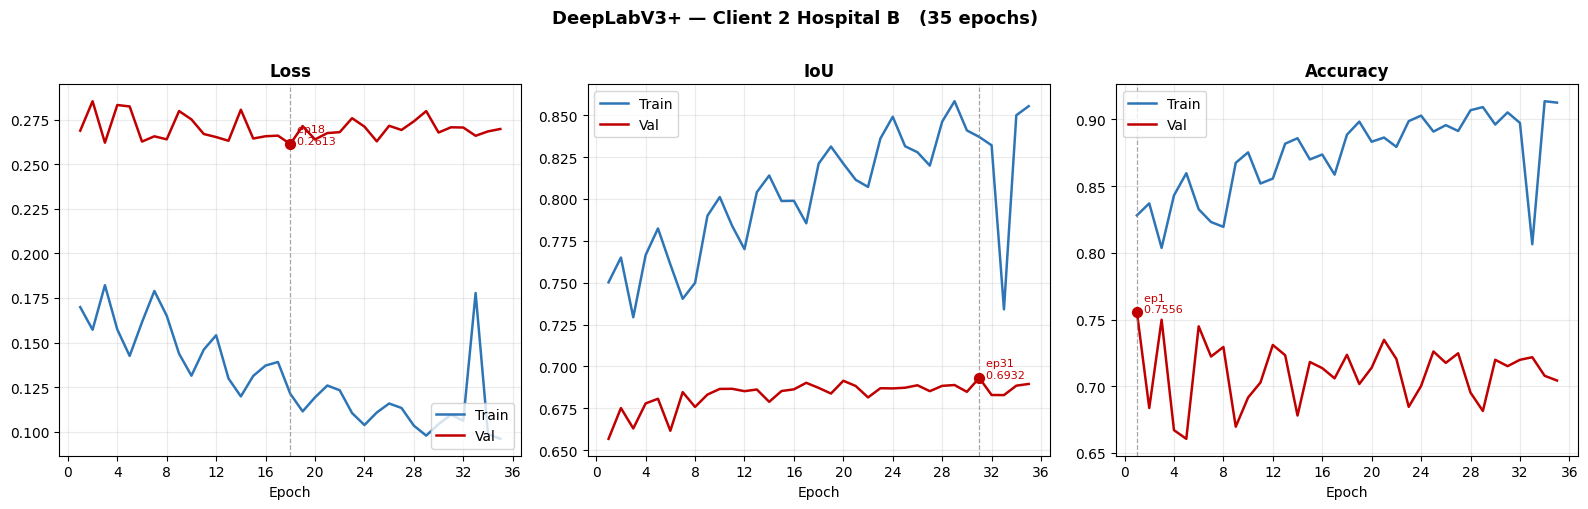


✓ Plot saved to Drive → /content/drive/MyDrive/BraTS2024_DeepLabV3/training_curves.png


In [ ]:
import json, os
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── Load history from Drive ───────────────────────────────────────────────────
HISTORY_DRIVE_PATH = "/content/drive/MyDrive/BraTS2024_DeepLabV3/history.json"

assert os.path.exists(HISTORY_DRIVE_PATH), (
    f"History file not found: {HISTORY_DRIVE_PATH}\n"
    "Make sure training has run at least 1 epoch with the updated Cell 15."
)

with open(HISTORY_DRIVE_PATH, "r") as f:
    history = json.load(f)

n_epochs = len(history["train_loss"])
epochs   = list(range(1, n_epochs + 1))
print(f"✓ Loaded history — {n_epochs} epochs recorded")
print(f"  Best val loss : {min(history['val_loss']):.4f}  (epoch {history['val_loss'].index(min(history['val_loss']))+1})")
print(f"  Best val IoU  : {max(history['val_iou']):.4f}   (epoch {history['val_iou'].index(max(history['val_iou']))+1})")

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

panels = [
    ("Loss",     "train_loss", "val_loss",  "lower right"),
    ("IoU",      "train_iou",  "val_iou",   "upper left"),
    ("Accuracy", "train_acc",  "val_acc",   "upper left"),
]

for ax, (title, tr_key, vl_key, leg_loc) in zip(axes, panels):
    ax.plot(epochs, history[tr_key], label="Train", color="#2E75B6", linewidth=1.8)
    ax.plot(epochs, history[vl_key], label="Val",   color="#C00000", linewidth=1.8)

    # Mark best val epoch
    if "loss" in vl_key:
        best_ep  = history[vl_key].index(min(history[vl_key])) + 1
        best_val = min(history[vl_key])
    else:
        best_ep  = history[vl_key].index(max(history[vl_key])) + 1
        best_val = max(history[vl_key])

    ax.axvline(best_ep, color="grey", linestyle="--", linewidth=0.9, alpha=0.7)
    ax.scatter([best_ep], [best_val], color="#C00000", zorder=5, s=50)
    ax.annotate(f"  ep{best_ep}\n  {best_val:.4f}",
                xy=(best_ep, best_val), fontsize=8, color="#C00000")

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel("Epoch")
    ax.legend(loc=leg_loc)
    ax.grid(True, alpha=0.25)
    ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.suptitle(
    f"DeepLabV3+ — Client 2 Hospital B   ({n_epochs} epochs)",
    fontsize=13, fontweight='bold', y=1.01
)
plt.tight_layout()

# Save PNG to Drive
PLOT_SAVE_PATH = "/content/drive/MyDrive/BraTS2024_DeepLabV3/training_curves.png"
plt.savefig(PLOT_SAVE_PATH, dpi=150, bbox_inches='tight')
plt.show()
print(f"\n✓ Plot saved to Drive → {PLOT_SAVE_PATH}")


## Cell 17 — Inference Visualization

In [ ]:
@torch.inference_mode()
def run_inference(model, loader, device, num_batches=3):
    model.eval()
    CLASS_NAMES  = ["Background", "NCR", "Edema", "ET"]
    CLASS_COLORS = ["#6a0dad", "#1f77b4", "#2ca02c", "#FFD700"]
    MODALITY_NAMES = ["T1n", "T1ce", "T2-FLAIR", "T2w"]
    cmap = plt.cm.colors.ListedColormap(CLASS_COLORS)
    fig_count = 0
    for batch_idx, (data, target) in enumerate(loader):
        if fig_count >= num_batches:
            break
        data   = data.to(device).float()
        target = target.to(device).float()
        seg_out, _, _ = model(data)
        pred       = seg_out.argmax(dim=1).cpu().numpy()
        target_cls = target.argmax(dim=1).cpu().numpy()
        data_np    = data.cpu().numpy()
        for b in range(min(data.shape[0], 2)):
            fig, axes = plt.subplots(1, 6, figsize=(22, 4))
            for m_idx in range(4):
                axes[m_idx].imshow(data_np[b, m_idx], cmap='gray')
                axes[m_idx].set_title(MODALITY_NAMES[m_idx], fontsize=10)
                axes[m_idx].axis('off')
            axes[4].imshow(target_cls[b], cmap=cmap, vmin=0, vmax=3)
            axes[4].set_title("Ground Truth", fontsize=10)
            axes[4].axis('off')
            axes[5].imshow(pred[b], cmap=cmap, vmin=0, vmax=3)
            axes[5].set_title("Prediction", fontsize=10)
            axes[5].axis('off')
            patches = [mpatches.Patch(color=c, label=n)
                       for c, n in zip(CLASS_COLORS, CLASS_NAMES)]
            fig.legend(handles=patches, loc='lower center', ncol=4, fontsize=9)
            plt.suptitle(f"Batch {batch_idx+1} | Sample {b+1}", fontsize=11)
            plt.tight_layout()
            plt.show()
            fig_count += 1


## Cell 18 — Run Full Pipeline

✓ Found 811 valid cases in /content/drive/MyDrive/client B dataset/Client_2_Hospital_B
✓ Selected 500 cases for training
✓ Found 500 preprocessed files on Drive
✓ Train/val split already exists on Drive
✓ Train dataset ready — 375 volumes × 8 slices = 3000 total
Extracting validation slices into cache...
✓ 500 validation slices cached (131 MB)
Image batch : torch.Size([4, 4, 128, 128])
Mask  batch : torch.Size([4, 4, 128, 128])
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 143MB/s]


Checkpoint dir: model_checkpoint/DeepLabV3_BraTS2024/version_0
✓ Checkpoint found: /content/drive/MyDrive/BraTS2024_DeepLabV3/checkpoints/latest_ckpt.tar
✓ Resumed from epoch 50 (val_loss=0.2698, val_IoU=0.6896)
✓ Training already complete — best checkpoint at epoch 50
  Best val loss : 0.2698
  Skipping training. Running inference only.

✓ Best model loaded
  Epoch     : 48
  Val loss  : 0.2659
  Val IoU   : 0.6829


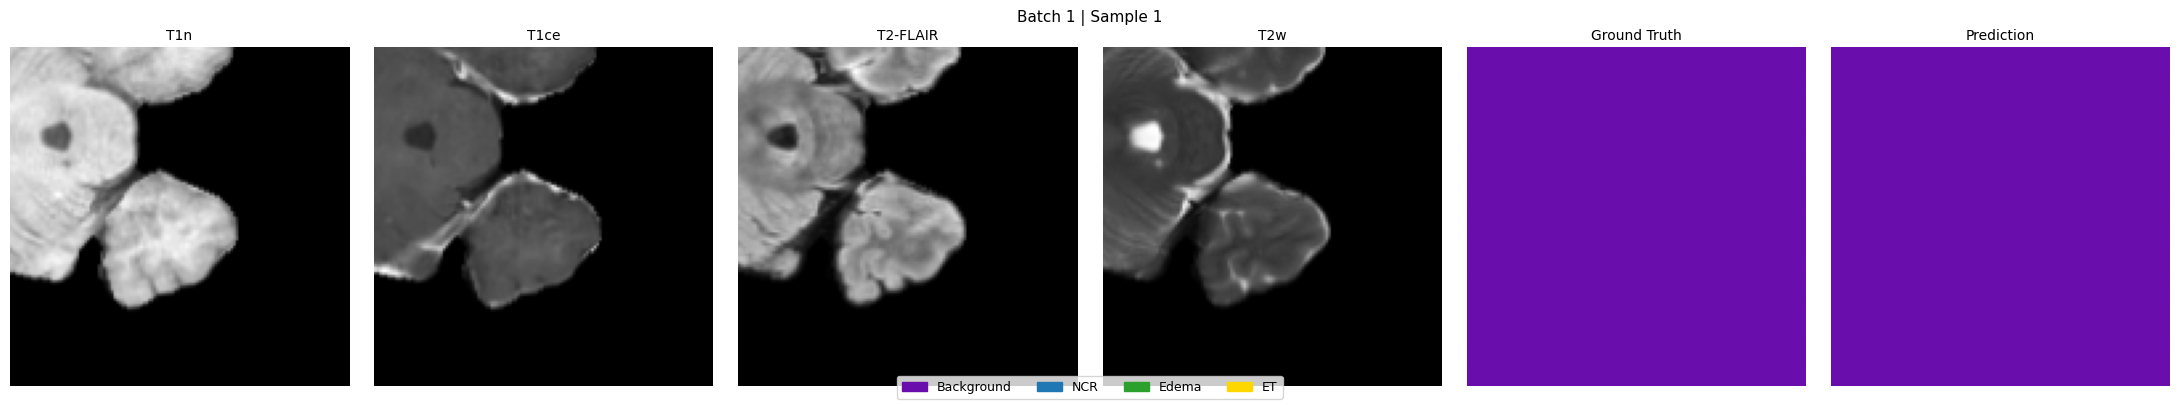

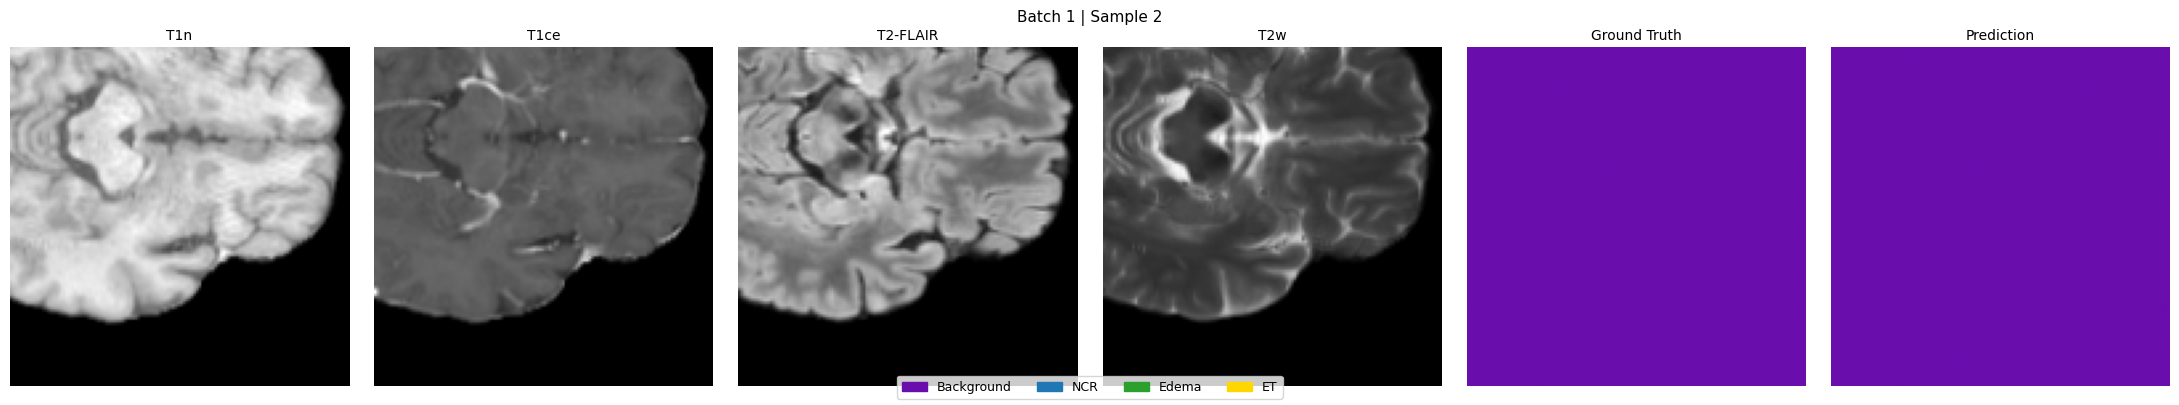

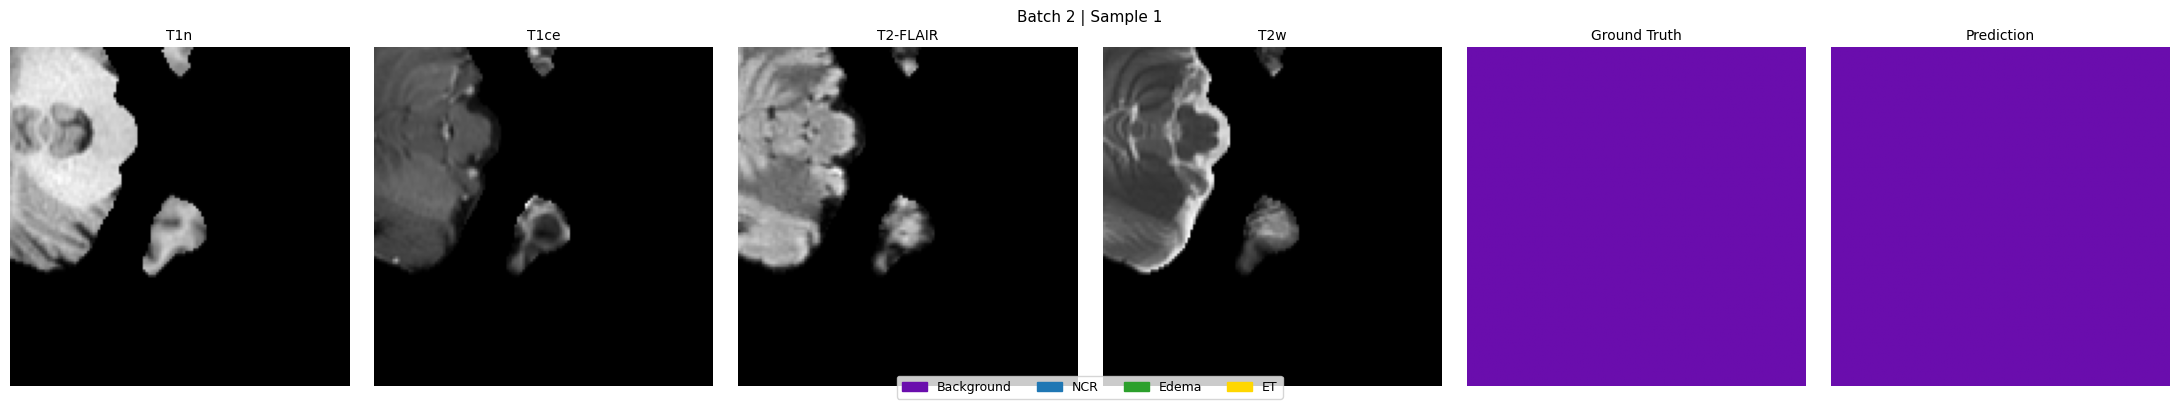

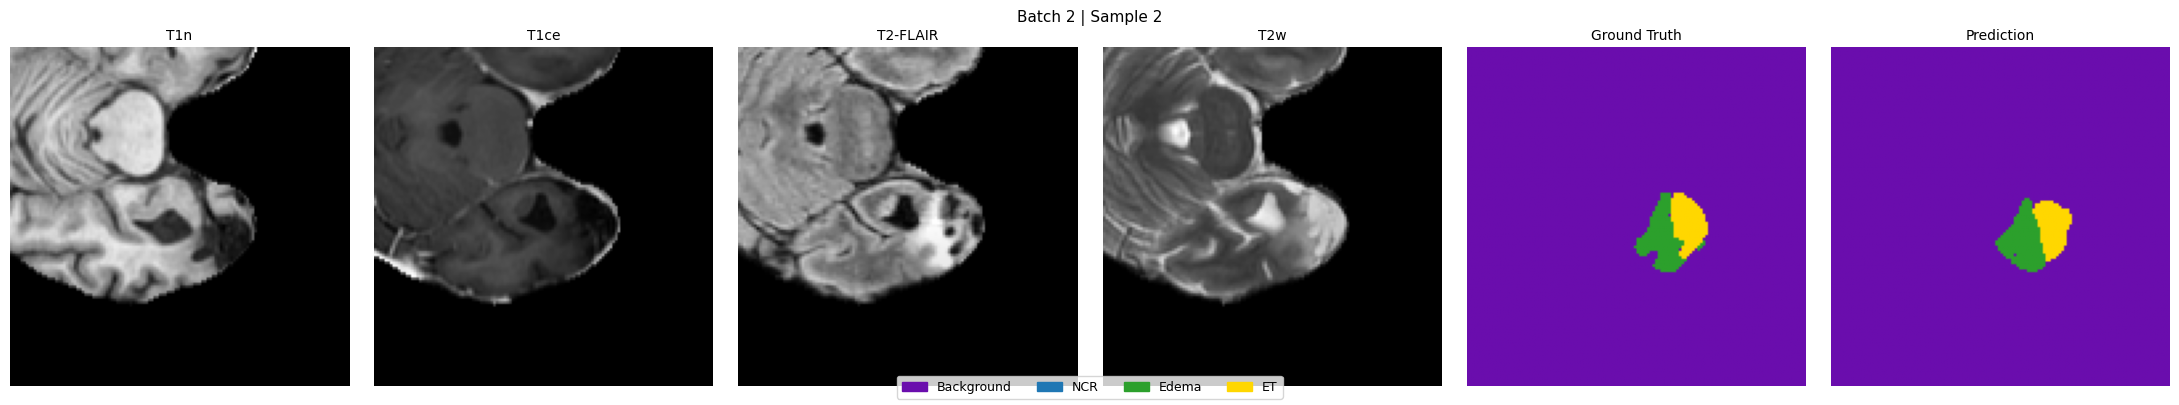

In [ ]:
# ── 1. Collect valid cases ───────────────────────────────────────────────────
valid_cases = collect_cases(CFG.DATASET_PATH)
selected    = sample_files(valid_cases, CFG.NUM_FILES_TO_USE, CFG.RANDOM_SEED)

# ── 2. Preprocess ────────────────────────────────────────────────────────────
drive_preproc     = os.path.join(CFG.DRIVE_BASE, "preprocessed")
drive_preproc_img = os.path.join(drive_preproc, "images")

if os.path.exists(drive_preproc_img) and len(os.listdir(drive_preproc_img)) > 10:
    print(f"✓ Found {len(os.listdir(drive_preproc_img))} preprocessed files on Drive")
else:
    print("Preprocessing directly to Drive...")
    preprocess_dataset(CFG.DATASET_PATH, selected, drive_preproc)

# ── 3. Train/val split ───────────────────────────────────────────────────────
drive_train_img = os.path.join(drive_preproc, "train", "images")
if not (os.path.exists(drive_train_img) and len(os.listdir(drive_train_img)) > 0):
    create_train_val_split(drive_preproc, CFG.TRAIN_RATIO, CFG.RANDOM_SEED)
else:
    print("✓ Train/val split already exists on Drive")

# ── 4. DataLoaders ───────────────────────────────────────────────────────────
train_ds = BraTS2024SliceDataset(
    os.path.join(drive_preproc, "train", "images"),
    os.path.join(drive_preproc, "train", "masks"),
    augment=True,
)
val_ds = BraTS2024SliceDatasetFixed(
    os.path.join(drive_preproc, "val", "images"),
    os.path.join(drive_preproc, "val", "masks"),
)

train_loader = DataLoader(train_ds, batch_size=CFG.BATCH_SIZE, shuffle=True,
    num_workers=CFG.NUM_WORKERS, pin_memory=CFG.PIN_MEMORY,
    prefetch_factor=2, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=CFG.BATCH_SIZE, shuffle=False,
    num_workers=CFG.NUM_WORKERS, pin_memory=CFG.PIN_MEMORY)

imgs, msks = next(iter(train_loader))
print(f"Image batch : {imgs.shape}")
print(f"Mask  batch : {msks.shape}")

# ── 5. Model / Optimizer / Scheduler ─────────────────────────────────────────
model = DeepLabV3Plus(
    in_channels=CFG.IN_CHANNELS, num_classes=CFG.OUT_CHANNELS, pretrained=True
).to(DEVICE)

backbone_params = (list(model.layer0.parameters()) + list(model.layer1.parameters()) +
                   list(model.layer2.parameters()) + list(model.layer3.parameters()) +
                   list(model.layer4.parameters()))
new_params = (list(model.aspp.parameters()) + list(model.low_level_proj.parameters()) +
              list(model.decoder.parameters()) + list(model.seg_head.parameters()) +
              list(model.aux_head.parameters()))

optimizer = AdamW([
    {'params': backbone_params, 'lr': CFG.LEARNING_RATE * 0.1},
    {'params': new_params,      'lr': CFG.LEARNING_RATE},
], weight_decay=CFG.WEIGHT_DECAY, amsgrad=True)

scheduler = CosineAnnealingLR(optimizer, T_max=CFG.EPOCHS, eta_min=1e-6)

CKPT_DIR       = create_checkpoint_dir(CFG.CHECKPOINT_DIR)
DRIVE_CKPT_DIR = os.path.join(CFG.DRIVE_BASE, "checkpoints")

# ── 6. Auto-resume ────────────────────────────────────────────────────────────
start_epoch = 1
best_loss   = float("inf")

resume_paths = [
    os.path.join(DRIVE_CKPT_DIR, "latest_ckpt.tar"),
    os.path.join(DRIVE_CKPT_DIR, "best_ckpt.tar"),
    os.path.join(CKPT_DIR,       "latest_ckpt.tar"),
    os.path.join(CKPT_DIR,       "best_ckpt.tar"),
]
for ckpt_path in resume_paths:
    if os.path.exists(ckpt_path):
        print(f"✓ Checkpoint found: {ckpt_path}")
        start_epoch, best_loss = load_checkpoint(
            model, optimizer, scheduler, ckpt_path=ckpt_path, device=DEVICE)
        break
else:
    print("✗ No checkpoint found — starting fresh from epoch 1.")

# ── 7. Skip training — already complete ──────────────────────────────────────
print(f"✓ Training already complete — best checkpoint at epoch {start_epoch - 1}")
print(f"  Best val loss : {best_loss:.4f}")
print(f"  Skipping training. Running inference only.")

# ── 8. Final inference ───────────────────────────────────────────────────────
best_model = DeepLabV3Plus(
    in_channels=CFG.IN_CHANNELS, num_classes=CFG.OUT_CHANNELS, pretrained=False
).to(DEVICE)

ckpt = torch.load(
    os.path.join(DRIVE_CKPT_DIR, "best_ckpt.tar"),
    map_location=DEVICE
)
best_model.load_state_dict(ckpt["model"])
print(f"\n✓ Best model loaded")
print(f"  Epoch     : {ckpt['epoch']}")
print(f"  Val loss  : {ckpt['val_loss']:.4f}")
print(f"  Val IoU   : {ckpt['val_iou']:.4f}")

run_inference(best_model, val_loader, DEVICE, num_batches=3)

In [ ]:
import os, numpy as np, torch
from tqdm import tqdm
import torch.nn.functional as F

DRIVE_BASE     = "/content/drive/MyDrive/BraTS2024_DeepLabV3"
DRIVE_CKPT_DIR = os.path.join(DRIVE_BASE, "checkpoints")
FEAT_SAVE_PATH = os.path.join(DRIVE_BASE, "features", "feat_2d_round1.pt")
NUM_VOLUMES    = 20

os.makedirs(os.path.dirname(FEAT_SAVE_PATH), exist_ok=True)

# ── Load best checkpoint ──────────────────────────────────────────────────────
feat_model = DeepLabV3Plus(
    in_channels=CFG.IN_CHANNELS,
    num_classes=CFG.OUT_CHANNELS,
    pretrained=False
).to(DEVICE)

ckpt = torch.load(os.path.join(DRIVE_CKPT_DIR, "best_ckpt.tar"), map_location=DEVICE)
feat_model.load_state_dict(ckpt["model"])
feat_model.eval()
print(f"✓ Loaded best_ckpt.tar — epoch {ckpt['epoch']}, "
      f"val_loss={ckpt['val_loss']:.4f}, val_iou={ckpt['val_iou']:.4f}")

# ── Point to val images ───────────────────────────────────────────────────────
val_img_dir = os.path.join(DRIVE_BASE, "preprocessed", "val", "images")
if not os.path.exists(val_img_dir):
    val_img_dir = os.path.join(DRIVE_BASE, "preprocessed", "images")
    print("⚠ No val split — using full preprocessed folder")

vol_files     = sorted(os.listdir(val_img_dir))[:NUM_VOLUMES]
depth_indices = torch.linspace(0, 127, 16).long().tolist()
print(f"✓ {len(vol_files)} volumes ready")
print(f"  Depth indices: {depth_indices}")

# ── Extract ───────────────────────────────────────────────────────────────────
all_features = []

with torch.no_grad():
    for vol_idx, fname in enumerate(tqdm(vol_files, desc="Extracting")):

        vol = np.load(os.path.join(val_img_dir, fname))         # (H,W,D,C)
        vol = torch.from_numpy(vol).permute(3, 2, 0, 1).float() # (C,D,H,W)

        if vol.shape[1:] != (128, 128, 128):
            vol = F.interpolate(vol.unsqueeze(0), size=(128,128,128),
                                mode='trilinear', align_corners=False).squeeze(0)

        mean = vol.mean(dim=(1,2,3), keepdim=True)
        std  = vol.std(dim=(1,2,3),  keepdim=True).clamp(min=1e-6)
        vol  = (vol - mean) / std

        # Run ASPP on 16 evenly spaced depth slices and stack
        slice_features = []
        for z in depth_indices:
            slc = vol[:, z, :, :].unsqueeze(0).to(DEVICE)  # (1, 4, 128, 128)
            _, _, aspp_out = feat_model(slc)                # (1, 256, 16, 16)
            slice_features.append(aspp_out.cpu())
            del slc, aspp_out

        stacked = torch.stack(slice_features, dim=2)        # (1, 256, 16, 16, 16)
        all_features.append(stacked)

        print(f"  [{vol_idx+1:02d}/{NUM_VOLUMES}] {fname} — {stacked.shape}")
        del vol, slice_features, stacked
        torch.cuda.empty_cache()

# ── Save ──────────────────────────────────────────────────────────────────────
feat_2d = torch.cat(all_features, dim=0)   # (20, 256, 16, 16, 16)
torch.save(feat_2d, FEAT_SAVE_PATH)

print(f"\n✓ feat_2d_round1.pt saved")
print(f"  Shape : {feat_2d.shape}")
print(f"  Size  : {feat_2d.element_size() * feat_2d.nelement() / 1e6:.1f} MB")
print(f"  Path  : {FEAT_SAVE_PATH}")

✓ Loaded best_ckpt.tar — epoch 48, val_loss=0.2659, val_iou=0.6829
✓ 20 volumes ready
  Depth indices: [0, 8, 16, 25, 33, 42, 50, 59, 67, 76, 84, 93, 101, 110, 118, 127]


Extracting:   5%|▌         | 1/20 [00:01<00:26,  1.41s/it]

  [01/20] BraTS-GLI-00008-100.npy — torch.Size([1, 256, 16, 16, 16])


Extracting:  10%|█         | 2/20 [00:06<01:01,  3.44s/it]

  [02/20] BraTS-GLI-00485-101.npy — torch.Size([1, 256, 16, 16, 16])


...

Extracting:  95%|█████████▌| 19/20 [00:27<00:00,  1.04it/s]

  [19/20] BraTS-GLI-02102-101.npy — torch.Size([1, 256, 16, 16, 16])


Extracting: 100%|██████████| 20/20 [00:28<00:00,  1.43s/it]

  [20/20] BraTS-GLI-02105-107.npy — torch.Size([1, 256, 16, 16, 16])



✓ feat_2d_round1.pt saved
  Shape : torch.Size([20, 256, 16, 16, 16])
  Size  : 83.9 MB
  Path  : /content/drive/MyDrive/BraTS2024_DeepLabV3/features/feat_2d_round1.pt


## Cell 19 — Feature Extraction (Run After Training)
Change ROUND_NUM to 1, 2, or 3 before running each round.


In [ ]:
ROUND_NUM      = 1
CKPT_TO_LOAD   = f"round{ROUND_NUM}_ckpt.tar"
FEAT_SAVE_PATH = os.path.join(CFG.DRIVE_BASE, "features", f"feat_2d_round{ROUND_NUM}.pt")
NUM_VOLUMES    = 20

os.makedirs(os.path.dirname(FEAT_SAVE_PATH), exist_ok=True)

ckpt_path = os.path.join(CFG.DRIVE_BASE, "checkpoints", CKPT_TO_LOAD)
assert os.path.exists(ckpt_path), f"Checkpoint not found: {ckpt_path}"

feat_model = DeepLabV3Plus(
    in_channels=CFG.IN_CHANNELS, num_classes=CFG.OUT_CHANNELS, pretrained=False
).to(DEVICE)
ckpt = torch.load(ckpt_path, map_location=DEVICE)
feat_model.load_state_dict(ckpt["model"])
feat_model.eval()
print(f"✓ Loaded {CKPT_TO_LOAD} (epoch {ckpt['epoch']}, val_loss={ckpt['val_loss']:.4f})")

val_vol_img_dir  = os.path.join(CFG.DRIVE_BASE, "preprocessed", "val", "images")
vol_files = sorted(os.listdir(val_vol_img_dir))[:NUM_VOLUMES]
depth_indices = torch.linspace(0, 127, CFG.NUM_SLICES).long().tolist()
print(f"Depth indices: {depth_indices}")

all_features = []
with torch.no_grad():
    for vol_idx, fname in enumerate(tqdm(vol_files, desc="Extracting features")):
        vol = np.load(os.path.join(val_vol_img_dir, fname))
        vol = torch.from_numpy(vol).permute(3, 2, 0, 1).float()
        if vol.shape[1:] != (128, 128, 128):
            vol = F.interpolate(vol.unsqueeze(0), size=(128,128,128),
                                mode='trilinear', align_corners=False).squeeze(0)
        mean = vol.mean(dim=(1,2,3), keepdim=True)
        std  = vol.std(dim=(1,2,3),  keepdim=True).clamp(min=1e-6)
        vol  = (vol - mean) / std
        slice_features = []
        for z in depth_indices:
            img_slice = vol[:, z, :, :].unsqueeze(0).to(DEVICE)
            _, _, aspp_out = feat_model(img_slice)
            slice_features.append(aspp_out.cpu())
        stacked = torch.stack(slice_features, dim=2)
        all_features.append(stacked)

feat_2d = torch.cat(all_features, dim=0)
torch.save(feat_2d, FEAT_SAVE_PATH)
print(f"\n✓ Feature tensor saved")
print(f"  Shape : {feat_2d.shape}")
print(f"  Path  : {FEAT_SAVE_PATH}")
print(f"  Size  : {feat_2d.element_size() * feat_2d.nelement() / 1e6:.1f} MB")
print(f"\n→ Share feat_2d_round{ROUND_NUM}.pt with Account 1 via Google Drive link.")

del feat_model, all_features
free_memory()


✓ Loaded round1_ckpt.tar (epoch 15, val_loss=0.2835)
Depth indices: [0, 8, 16, 25, 33, 42, 50, 59, 67, 76, 84, 93, 101, 110, 118, 127]


Extracting features: 100%|██████████| 20/20 [00:18<00:00,  1.09it/s]



✓ Feature tensor saved
  Shape : torch.Size([20, 256, 16, 16, 16])
  Path  : /content/drive/MyDrive/BraTS2024_DeepLabV3/features/feat_2d_round1.pt
  Size  : 83.9 MB

→ Share feat_2d_round1.pt with Account 1 via Google Drive link.


## Cell 20 — Guidance Injection Fine-Tuning (Rounds 2 & 3 Only)


In [ ]:
def create_dataloaders(cfg, drive_preproc_path):
    """Creates and returns train and validation DataLoader instances."""
    train_ds = BraTS2024SliceDataset(
        os.path.join(drive_preproc_path, "train", "images"),
        os.path.join(drive_preproc_path, "train", "masks"),
        augment=True,
    )
    val_ds = BraTS2024SliceDatasetFixed(
        os.path.join(drive_preproc_path, "val", "images"),
        os.path.join(drive_preproc_path, "val", "masks"),
    )

    train_loader = DataLoader(train_ds, batch_size=cfg.BATCH_SIZE, shuffle=True,
        num_workers=cfg.NUM_WORKERS, pin_memory=cfg.PIN_MEMORY,
        prefetch_factor=2, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=cfg.BATCH_SIZE, shuffle=False,
        num_workers=cfg.NUM_WORKERS, pin_memory=cfg.PIN_MEMORY)

    imgs, msks = next(iter(train_loader))
    print(f"Image batch : {imgs.shape}")
    print(f"Mask  batch : {msks.shape}")

    return train_loader, val_loader

print("✓ `create_dataloaders` function defined.")

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

ROUND_NUM        = 2
PREV_ROUND       = ROUND_NUM - 1
FINETUNE_EPOCHS  = 10
GUIDANCE_LR      = 5e-5

GUIDANCE_FILE_ID = "10BVbalrPuLuuoTfpXj9SSX00ibh7RQKK"
GUIDANCE_LOCAL   = f"/content/guidance_round{PREV_ROUND}.pt"
PREV_CKPT_PATH   = os.path.join(CFG.DRIVE_BASE, "checkpoints", f"round{PREV_ROUND}_ckpt.tar")

# New: Paths for fine-tuning checkpoints
FINETUNE_CKPT_DIR   = os.path.join(CFG.DRIVE_BASE, "checkpoints", f"finetune_round{ROUND_NUM}")
os.makedirs(FINETUNE_CKPT_DIR, exist_ok=True) # Ensure directory exists
LATEST_FT_CKPT_PATH = os.path.join(FINETUNE_CKPT_DIR, "latest_ft_ckpt.tar")
BEST_FT_CKPT_PATH   = os.path.join(FINETUNE_CKPT_DIR, f"round{ROUND_NUM}_ckpt.tar") # This will be the best for the round


# Ensure dataloaders are defined before use
drive_preproc = os.path.join(CFG.DRIVE_BASE, "preprocessed")
train_loader, val_loader = create_dataloaders(CFG, drive_preproc)

if not os.path.exists(GUIDANCE_LOCAL):
    import subprocess
    subprocess.run(["gdown", f"https://drive.google.com/uc?id={GUIDANCE_FILE_ID}",
                    "-O", GUIDANCE_LOCAL], check=True)

guidance_signal = torch.load(GUIDANCE_LOCAL, map_location=DEVICE)
guidance_mean = guidance_signal.mean(dim=0, keepdim=True)
print(f"✓ Guidance loaded — shape: {guidance_signal.shape}")

class DeepLabV3PlusGuided(DeepLabV3Plus):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.guidance_proj = nn.Sequential(
            nn.Conv2d(512, 256, 1, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(inplace=True),
        )
        for m in self.guidance_proj.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')

    def forward_with_guidance(self, x, guidance_3d):
        input_size = x.shape[-2:]
        x0  = self.layer0(x); x1 = self.layer1(x0)
        x2  = self.layer2(x1); x3 = self.layer3(x2); x4 = self.layer4(x3)
        aspp_out = self.aspp(x4)
        g_2d = guidance_3d.mean(dim=2).expand(x.shape[0], -1, -1, -1).to(x.device)
        if g_2d.shape[-2:] != aspp_out.shape[-2:]:
            g_2d = F.interpolate(g_2d, size=aspp_out.shape[-2:], mode='bilinear', align_corners=False)
        aspp_out = self.guidance_proj(torch.cat([aspp_out, g_2d], dim=1))
        low = self.low_level_proj(x1)
        aspp_up = F.interpolate(aspp_out, size=low.shape[-2:], mode='bilinear', align_corners=False)
        dec_out = self.decoder(torch.cat([aspp_up, low], dim=1))
        dec_up  = F.interpolate(dec_out, size=input_size, mode='bilinear', align_corners=False)
        return self.seg_head(dec_up), self.aux_head(dec_up), aspp_out

guided_model = DeepLabV3PlusGuided(
    in_channels=CFG.IN_CHANNELS, num_classes=CFG.OUT_CHANNELS, pretrained=False
).to(DEVICE)
ckpt = torch.load(PREV_CKPT_PATH, map_location=DEVICE)
guided_model.load_state_dict(ckpt["model"], strict=False)
print(f"✓ Loaded round{PREV_ROUND}_ckpt.tar as base model.")

ft_optimizer = AdamW(guided_model.parameters(), lr=GUIDANCE_LR,
                     weight_decay=CFG.WEIGHT_DECAY, amsgrad=True)
ft_scheduler = CosineAnnealingLR(ft_optimizer, T_max=FINETUNE_EPOCHS, eta_min=1e-6)
scaler       = torch.amp.GradScaler('cuda', enabled=CFG.AMP_ENABLED)

# Auto-resume logic for fine-tuning
start_ft_epoch = 1
best_ft_loss   = float('inf')

if os.path.exists(LATEST_FT_CKPT_PATH):
    print(f"✓ Resuming fine-tuning for Round {ROUND_NUM} from: {LATEST_FT_CKPT_PATH}")
    latest_ft_ckpt = torch.load(LATEST_FT_CKPT_PATH, map_location=DEVICE)
    guided_model.load_state_dict(latest_ft_ckpt["model"])
    ft_optimizer.load_state_dict(latest_ft_ckpt["optimizer"])
    if "scheduler" in latest_ft_ckpt:
        ft_scheduler.load_state_dict(latest_ft_ckpt["scheduler"])
    start_ft_epoch = latest_ft_ckpt["epoch"] + 1
    best_ft_loss   = latest_ft_ckpt["val_loss"]
    print(f"  Resumed from epoch {latest_ft_ckpt['epoch']} (val_loss={latest_ft_ckpt['val_loss']:.4f})")
else:
    print(f"✗ No previous fine-tuning checkpoint found for Round {ROUND_NUM}. Starting from epoch 1.")

for ft_epoch in range(start_ft_epoch, FINETUNE_EPOCHS + 1):
    guided_model.train()
    ft_loss_sum, ft_steps = 0.0, 0
    ft_optimizer.zero_grad()
    with tqdm(total=len(train_loader), ncols=115, desc=f"FT Train | {ft_epoch:02d}/{FINETUNE_EPOCHS}") as pbar_train:
        for step, (data, target) in enumerate(train_loader):
            data   = data.to(DEVICE).float()
            target = target.to(DEVICE).float()
            target_cls    = target.argmax(dim=1)
            target_binary = (target_cls > 0).unsqueeze(1).float()
            with torch.amp.autocast('cuda', enabled=CFG.AMP_ENABLED):
                seg, aux, _ = guided_model.forward_with_guidance(data, guidance_mean)
                loss = combined_loss(seg, aux, target_cls, target_binary) / CFG.GRAD_ACCUM_STEPS
            scaler.scale(loss).backward()
            if (step + 1) % CFG.GRAD_ACCUM_STEPS == 0:
                scaler.unscale_(ft_optimizer)
                torch.nn.utils.clip_grad_norm_(guided_model.parameters(), 1.0)
                scaler.step(ft_optimizer); scaler.update(); ft_optimizer.zero_grad()
            ft_loss_sum += loss.item() * CFG.GRAD_ACCUM_STEPS; ft_steps += 1
            pbar_train.update(1)
            pbar_train.set_postfix_str(f"Loss:{loss.item()*CFG.GRAD_ACCUM_STEPS:.4f}")
    ft_scheduler.step()

    guided_model.eval()
    val_loss_sum, val_steps = 0.0, 0
    with tqdm(total=len(val_loader), ncols=115, desc=f"FT Valid | {ft_epoch:02d}/{FINETUNE_EPOCHS}") as pbar_val:
        with torch.no_grad():
            for data, target in val_loader:
                data   = data.to(DEVICE).float(); target = target.to(DEVICE).float()
                target_cls    = target.argmax(dim=1)
                target_binary = (target_cls > 0).unsqueeze(1).float()
                with torch.amp.autocast('cuda', enabled=CFG.AMP_ENABLED):
                    seg, aux, _ = guided_model.forward_with_guidance(data, guidance_mean)
                    loss = combined_loss(seg, aux, target_cls, target_binary)
                val_loss_sum += loss.item(); val_steps += 1
                pbar_val.update(1)
                pbar_val.set_postfix_str(f"Loss:{loss.item():.4f}")

    avg_train = ft_loss_sum / ft_steps
    avg_val   = val_loss_sum / val_steps
    print(f"[FT {ft_epoch:02d}/{FINETUNE_EPOCHS}]  Train: {avg_train:.4f}  Val: {avg_val:.4f}")

    # Save latest fine-tuning checkpoint for auto-resume
    latest_ft_ckpt_state = {
        'epoch': ft_epoch,
        'model': guided_model.state_dict(),
        'optimizer': ft_optimizer.state_dict(),
        'scheduler': ft_scheduler.state_dict(),
        'val_loss': avg_val,
        # 'val_iou': 0.0 # IoU not computed in FT validation, but can be added if needed
    }
    torch.save(latest_ft_ckpt_state, LATEST_FT_CKPT_PATH)
    print(f"  ✓ Latest fine-tuning checkpoint saved to {LATEST_FT_CKPT_PATH}")


    if avg_val < best_ft_loss:
        best_ft_loss = avg_val
        # Save the best model for the round
        torch.save(latest_ft_ckpt_state, BEST_FT_CKPT_PATH) # Save the same structure as latest
        print(f"  ★ round{ROUND_NUM}_ckpt.tar saved (new best val_loss: {best_ft_loss:.4f})")

print(f"\n✓ Round {ROUND_NUM} fine-tuning complete. Best val loss: {best_ft_loss:.4f}")
free_memory()

✓ Train dataset ready — 375 volumes × 8 slices = 3000 total
Extracting validation slices into cache...
✓ 500 validation slices cached (131 MB)
Image batch : torch.Size([4, 4, 128, 128])
Mask  batch : torch.Size([4, 4, 128, 128])
✓ Guidance loaded — shape: torch.Size([20, 256, 16, 16, 16])
✓ Loaded round1_ckpt.tar as base model.
✓ Resuming fine-tuning for Round 2 from: /content/drive/MyDrive/BraTS2024_DeepLabV3/checkpoints/finetune_round2/latest_ft_ckpt.tar
  Resumed from epoch 7 (val_loss=0.2442)


FT Train | 08/10: 100%|█████████████████████████████████████████████| 750/750 [47:31<00:00,  3.80s/it, Loss:0.1687]
FT Valid | 08/10: 100%|█████████████████████████████████████████████| 125/125 [00:03<00:00, 34.94it/s, Loss:0.2903]


[FT 08/10]  Train: 0.1582  Val: 0.2505
  ✓ Latest fine-tuning checkpoint saved to /content/drive/MyDrive/BraTS2024_DeepLabV3/checkpoints/finetune_round2/latest_ft_ckpt.tar


FT Train | 09/10: 100%|█████████████████████████████████████████████| 750/750 [48:31<00:00,  3.88s/it, Loss:0.2793]
FT Valid | 09/10: 100%|█████████████████████████████████████████████| 125/125 [00:03<00:00, 38.61it/s, Loss:0.3060]


[FT 09/10]  Train: 0.1708  Val: 0.2365
  ✓ Latest fine-tuning checkpoint saved to /content/drive/MyDrive/BraTS2024_DeepLabV3/checkpoints/finetune_round2/latest_ft_ckpt.tar
  ★ round2_ckpt.tar saved (new best val_loss: 0.2365)


FT Train | 10/10: 100%|█████████████████████████████████████████████| 750/750 [49:19<00:00,  3.95s/it, Loss:0.1815]
FT Valid | 10/10: 100%|█████████████████████████████████████████████| 125/125 [00:03<00:00, 36.86it/s, Loss:0.2968]


[FT 10/10]  Train: 0.1720  Val: 0.2361
  ✓ Latest fine-tuning checkpoint saved to /content/drive/MyDrive/BraTS2024_DeepLabV3/checkpoints/finetune_round2/latest_ft_ckpt.tar
  ★ round2_ckpt.tar saved (new best val_loss: 0.2361)

✓ Round 2 fine-tuning complete. Best val loss: 0.2361


### Fine-tuning History Plot from Provided Data

Below is the plot generated using the epoch, training loss, and validation loss data you just provided. This visually represents the performance of the fine-tuning process for Round 2.

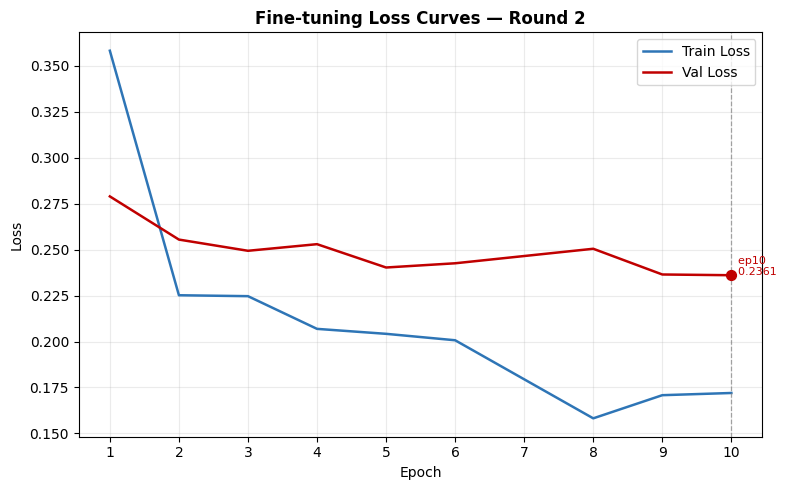

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

epochs = [1,2,3,4,5,6,8,9,10]
train_loss = [0.3583, 0.2252, 0.2247, 0.2069, 0.2042, 0.2007, 0.1582, 0.1708, 0.1720]
val_loss   = [0.2790, 0.2555, 0.2494, 0.2530, 0.2403, 0.2426, 0.2505, 0.2365, 0.2361]


# Ensure all lists are numpy arrays for easier manipulation
epochs_np = np.array(epochs)
train_loss_np = np.array(train_loss)
val_loss_np = np.array(val_loss)

fig, ax = plt.subplots(1, 1, figsize=(8, 5))

ax.plot(epochs_np, train_loss_np, label="Train Loss", color="#2E75B6", linewidth=1.8)
ax.plot(epochs_np, val_loss_np, label="Val Loss",   color="#C00000", linewidth=1.8)

# Mark best val loss epoch
if len(val_loss_np) > 0:
    best_val_loss = np.min(val_loss_np)
    best_epoch_idx = np.argmin(val_loss_np)
    best_ep_loss  = epochs_np[best_epoch_idx]

    ax.axvline(best_ep_loss, color="grey", linestyle="--", linewidth=0.9, alpha=0.7)
    ax.scatter([best_ep_loss], [best_val_loss], color="#C00000", zorder=5, s=50)
    ax.annotate(f"  ep{best_ep_loss}\n  {best_val_loss:.4f}",
                xy=(best_ep_loss, best_val_loss), fontsize=8, color="#C00000")

ax.set_title(f"Fine-tuning Loss Curves — Round 2", fontsize=12, fontweight='bold')
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.25)
ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

# Optional: Save PNG to Drive (using previous path if defined)
# If you wish to save this plot, ensure DRIVE_BASE and FINETUNE_CKPT_DIR are defined
# and uncomment the following lines:
# import os
# DRIVE_BASE = '/content/drive/MyDrive/BraTS2024_DeepLabV3'
# ROUND_NUM_TO_PLOT = 2 # Or whichever round this data corresponds to
# FINETUNE_CKPT_DIR = os.path.join(DRIVE_BASE, "checkpoints", f"finetune_round{ROUND_NUM_TO_PLOT}")
# os.makedirs(FINETUNE_CKPT_DIR, exist_ok=True)
# PLOT_SAVE_PATH_FT = os.path.join(FINETUNE_CKPT_DIR, f"finetune_training_curves_round{ROUND_NUM_TO_PLOT}_manual.png")
# plt.savefig(PLOT_SAVE_PATH_FT, dpi=150, bbox_inches='tight')
# print(f"\n✓ Fine-tuning plot saved to Drive → {PLOT_SAVE_PATH_FT}")

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class DeepLabV3PlusGuided(DeepLabV3Plus):
    """
    DeepLabV3+ with guidance injection at the ASPP output.
    Extends the base DeepLabV3Plus with a guidance_proj layer that
    concatenates the guidance signal with ASPP features before decoding.

    Used for Round 2 and Round 3 guided fine-tuning.
    Guidance shape: (B, 256, 16, 16, 16) — collapsed to 2D before injection.
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.guidance_proj = nn.Sequential(
            nn.Conv2d(512, 256, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )
        # Initialize guidance_proj weights
        for m in self.guidance_proj.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out',
                                        nonlinearity='relu')

    def forward_with_guidance(self, x, guidance_3d):
        """
        x           : (B, 4, 128, 128)       — input MRI slice
        guidance_3d : (1, 256, 16, 16, 16)   — server guidance signal
        Returns     : seg (B,4,128,128), aux (B,1,128,128), aspp_out (B,256,16,16)
        """
        input_size = x.shape[-2:]

        # Encoder
        x0  = self.layer0(x)
        x1  = self.layer1(x0)
        x2  = self.layer2(x1)
        x3  = self.layer3(x2)
        x4  = self.layer4(x3)

        # ASPP
        aspp_out = self.aspp(x4)                               # (B, 256, 16, 16)

        # Guidance injection — collapse depth by mean → 2D
        g_2d = guidance_3d.mean(dim=2)                        # (1, 256, 16, 16)
        g_2d = g_2d.expand(x.shape[0], -1, -1, -1).to(x.device)  # (B, 256, 16, 16)
        if g_2d.shape[-2:] != aspp_out.shape[-2:]:
            g_2d = F.interpolate(g_2d, size=aspp_out.shape[-2:],
                                 mode='bilinear', align_corners=False)

        # Concat + project back to 256 channels
        aspp_out = self.guidance_proj(
            torch.cat([aspp_out, g_2d], dim=1)                # (B, 512, 16, 16)
        )                                                      # (B, 256, 16, 16)

        # Decoder
        low     = self.low_level_proj(x1)                     # (B,  48, 32, 32)
        aspp_up = F.interpolate(aspp_out, size=low.shape[-2:],
                                mode='bilinear', align_corners=False)
        dec_out = self.decoder(torch.cat([aspp_up, low], dim=1))
        dec_up  = F.interpolate(dec_out, size=input_size,
                                mode='bilinear', align_corners=False)

        seg = self.seg_head(dec_up)                            # (B, 4, 128, 128)
        aux = self.aux_head(dec_up)                            # (B, 1, 128, 128)

        return seg, aux, aspp_out

    def forward(self, x):
        """Standard forward without guidance — used for plain inference."""
        return super().forward(x)


# ── Sanity check ──────────────────────────────────────────────────────────────
test_model = DeepLabV3PlusGuided(
    in_channels=4, num_classes=4, pretrained=False
).to(DEVICE)

with torch.no_grad():
    dummy_slice    = torch.randn(2, 4, 128, 128).to(DEVICE)
    dummy_guidance = torch.randn(1, 256, 16, 16, 16).to(DEVICE)
    seg, aux, aspp = test_model.forward_with_guidance(dummy_slice, dummy_guidance)

assert seg.shape  == (2, 4, 128, 128), f"seg wrong: {seg.shape}"
assert aux.shape  == (2, 1, 128, 128), f"aux wrong: {aux.shape}"
assert aspp.shape == (2, 256, 16, 16), f"aspp wrong: {aspp.shape}"

total = sum(p.numel() for p in test_model.parameters())
print(f"✓ DeepLabV3PlusGuided defined and verified")
print(f"  seg  : {seg.shape}")
print(f"  aux  : {aux.shape}")
print(f"  aspp : {aspp.shape}")
print(f"  Params: {total:,}")

del test_model, dummy_slice, dummy_guidance, seg, aux, aspp
torch.cuda.empty_cache()

✓ DeepLabV3PlusGuided defined and verified
  seg  : torch.Size([2, 4, 128, 128])
  aux  : torch.Size([2, 1, 128, 128])
  aspp : torch.Size([2, 256, 16, 16])
  Params: 40,630,181


In [ ]:
import gdown, os, torch

# guidance_round1.pt is on the server Drive — download it directly
GUIDANCE_FILE_ID = "10BVbalrPuLuuoTfpXj9SSX00ibh7RQKK"
GUIDANCE_PATH    = "/content/drive/MyDrive/BraTS2024_DeepLabV3/guidance_round1.pt"

if not os.path.exists(GUIDANCE_PATH):
    print("Downloading guidance_round1.pt from server Drive...")
    gdown.download(
        f"https://drive.google.com/uc?id={GUIDANCE_FILE_ID}",
        GUIDANCE_PATH, quiet=False
    )
else:
    print("✓ guidance_round1.pt already exists")

# Verify
guidance      = torch.load(GUIDANCE_PATH, map_location='cpu')
guidance_mean = guidance.mean(dim=0, keepdim=True).to(DEVICE)
print(f"✓ guidance_round1.pt loaded")
print(f"  Shape : {guidance.shape}")
print(f"  Mean  : {guidance.mean():.4f}")
print(f"  Max   : {guidance.max():.4f}")

Downloading...
From (original): https://drive.google.com/uc?id=10BVbalrPuLuuoTfpXj9SSX00ibh7RQKK
From (redirected): https://drive.google.com/uc?id=10BVbalrPuLuuoTfpXj9SSX00ibh7RQKK&confirm=t&uuid=7cfaa7dc-ef72-4def-bd1b-acca03239829
To: /content/drive/MyDrive/BraTS2024_DeepLabV3/guidance_round1.pt
100%|██████████| 83.9M/83.9M [00:00<00:00, 105MB/s] 


✓ guidance_round1.pt loaded
  Shape : torch.Size([20, 256, 16, 16, 16])
  Mean  : 0.1783
  Max   : 14.7007


In [ ]:
# ─────────────────────────────────────────────────────────────
# DEEPLABV3+ SPECIFIC PATHS FOR EVALUATION
# ─────────────────────────────────────────────────────────────
DL_BEST_CKPT_PATH   = os.path.join(CFG.DRIVE_BASE, "checkpoints", "best_ckpt.tar")
DL_ROUND2_CKPT_PATH = os.path.join(CFG.DRIVE_BASE, "checkpoints", "finetune_round2", "round2_ckpt.tar")
DL_GUIDANCE_PATH    = os.path.join(CFG.DRIVE_BASE, "guidance_round1.pt") # This is the server guidance that was downloaded

print("✓ DeepLabV3+ specific evaluation paths defined:")
print(f"  Best Ckpt  : {DL_BEST_CKPT_PATH}")
print(f"  Round 2 Ckpt: {DL_ROUND2_CKPT_PATH}")
print(f"  Guidance   : {DL_GUIDANCE_PATH}")

✓ DeepLabV3+ specific evaluation paths defined:
  Best Ckpt  : /content/drive/MyDrive/BraTS2024_DeepLabV3/checkpoints/best_ckpt.tar
  Round 2 Ckpt: /content/drive/MyDrive/BraTS2024_DeepLabV3/checkpoints/finetune_round2/round2_ckpt.tar
  Guidance   : /content/drive/MyDrive/BraTS2024_DeepLabV3/guidance_round1.pt


In [ ]:
import os, numpy as np, torch
from tqdm import tqdm
import torch.nn.functional as F

DRIVE_BASE     = '/content/drive/MyDrive/BraTS2024_DeepLabV3'
DRIVE_CKPT_DIR = os.path.join(DRIVE_BASE, 'checkpoints')
FEAT_SAVE_PATH = os.path.join(DRIVE_BASE, 'features', 'feat_2d_round2.pt')
ROUND2_CKPT    = os.path.join(DRIVE_CKPT_DIR, 'round2_ckpt.tar')
GUIDANCE_PATH  = os.path.join(DRIVE_BASE, 'guidance_round1.pt')
NUM_VOLUMES    = 20

os.makedirs(os.path.dirname(FEAT_SAVE_PATH), exist_ok=True)

# ── Load round2 guided model ──────────────────────────────────────────────────
feat_model = DeepLabV3PlusGuided(
    in_channels=CFG.IN_CHANNELS,
    num_classes=CFG.OUT_CHANNELS,
    pretrained=False
).to(DEVICE)

ckpt = torch.load(ROUND2_CKPT, map_location=DEVICE)
feat_model.load_state_dict(ckpt['model'], strict=False)
feat_model.eval()
print(f"✓ round2_ckpt.tar loaded")
print(f"  Epoch   : {ckpt['epoch']}")
print(f"  Val Loss: {ckpt['val_loss']:.4f}")

# ── Load guidance mean ────────────────────────────────────────────────────────
guidance      = torch.load(GUIDANCE_PATH, map_location='cpu')
guidance_mean = guidance.mean(dim=0, keepdim=True).to(DEVICE)
print(f"✓ guidance_round1.pt loaded — shape {guidance.shape}")

# ── Val images ────────────────────────────────────────────────────────────────
val_img_dir = os.path.join(DRIVE_BASE, 'preprocessed', 'val', 'images')
if not os.path.exists(val_img_dir):
    val_img_dir = os.path.join(DRIVE_BASE, 'preprocessed', 'images')
    print("⚠ Using full preprocessed folder")

vol_files     = sorted(os.listdir(val_img_dir))[:NUM_VOLUMES]
depth_indices = torch.linspace(0, 127, 16).long().tolist()
print(f"✓ {len(vol_files)} volumes ready")

# ── Extract ASPP features with guidance injected ──────────────────────────────
all_features = []

with torch.no_grad():
    for vol_idx, fname in enumerate(tqdm(vol_files, desc="Extracting R2 features")):
        vol = np.load(os.path.join(val_img_dir, fname))
        vol = torch.from_numpy(vol).permute(3, 2, 0, 1).float()

        if vol.shape[1:] != (128, 128, 128):
            vol = F.interpolate(vol.unsqueeze(0), size=(128,128,128),
                                mode='trilinear', align_corners=False).squeeze(0)

        mean = vol.mean(dim=(1,2,3), keepdim=True)
        std  = vol.std(dim=(1,2,3),  keepdim=True).clamp(min=1e-6)
        vol  = (vol - mean) / std

        slice_features = []
        for z in depth_indices:
            slc = vol[:, z, :, :].unsqueeze(0).to(DEVICE)   # (1, 4, 128, 128)

            # Forward through encoder + ASPP with guidance injected
            x0  = feat_model.layer0(slc)
            x1  = feat_model.layer1(x0)
            x2  = feat_model.layer2(x1)
            x3  = feat_model.layer3(x2)
            x4  = feat_model.layer4(x3)
            aspp_out = feat_model.aspp(x4)                   # (1, 256, 16, 16)

            # Apply guidance projection (same as during training)
            g_2d = guidance_mean.mean(dim=2).expand(1, -1, -1, -1).to(DEVICE)
            if g_2d.shape[-2:] != aspp_out.shape[-2:]:
                g_2d = F.interpolate(g_2d, size=aspp_out.shape[-2:],
                                     mode='bilinear', align_corners=False)
            enriched = feat_model.guidance_proj(
                torch.cat([aspp_out, g_2d], dim=1)
            )                                                 # (1, 256, 16, 16)

            slice_features.append(enriched.cpu())
            del slc, aspp_out, g_2d, enriched

        stacked = torch.stack(slice_features, dim=2)         # (1, 256, 16, 16, 16)
        all_features.append(stacked)
        print(f"  [{vol_idx+1:02d}/{NUM_VOLUMES}] {fname} — {stacked.shape}")
        del vol, slice_features, stacked
        torch.cuda.empty_cache()

# ── Save ──────────────────────────────────────────────────────────────────────
feat_2d_r2 = torch.cat(all_features, dim=0)   # (20, 256, 16, 16, 16)
torch.save(feat_2d_r2, FEAT_SAVE_PATH)

print(f"\n✓ feat_2d_round2.pt saved")
print(f"  Shape : {feat_2d_r2.shape}")
print(f"  Size  : {feat_2d_r2.element_size() * feat_2d_r2.nelement() / 1e6:.1f} MB")
print(f"  Path  : {FEAT_SAVE_PATH}")

✓ round2_ckpt.tar loaded
  Epoch   : 6
  Val Loss: 0.2361
✓ guidance_round1.pt loaded — shape torch.Size([20, 256, 16, 16, 16])
✓ 20 volumes ready


Extracting R2 features:   5%|▌         | 1/20 [00:01<00:30,  1.61s/it]

  [01/20] BraTS-GLI-00008-100.npy — torch.Size([1, 256, 16, 16, 16])


Extracting R2 features:  10%|█         | 2/20 [00:03<00:27,  1.51s/it]

  [02/20] BraTS-GLI-00485-101.npy — torch.Size([1, 256, 16, 16, 16])


...

Extracting R2 features:  95%|█████████▌| 19/20 [00:18<00:00,  1.10it/s]

  [19/20] BraTS-GLI-02102-101.npy — torch.Size([1, 256, 16, 16, 16])


Extracting R2 features: 100%|██████████| 20/20 [00:19<00:00,  1.05it/s]

  [20/20] BraTS-GLI-02105-107.npy — torch.Size([1, 256, 16, 16, 16])



✓ feat_2d_round2.pt saved
  Shape : torch.Size([20, 256, 16, 16, 16])
  Size  : 83.9 MB
  Path  : /content/drive/MyDrive/BraTS2024_DeepLabV3/features/feat_2d_round2.pt


# VISUALISATION

In [ ]:
regions = ['WT', 'TC', 'ET'] # Whole Tumor, Tumor Core, Enhancing Tumor
metrics = ['dice', 'iou', 'sensitivity', 'specificity', 'hd95'] # Dice, IoU, Sensitivity, Specificity, Hausdorff Distance 95

def dice_score(pred, true, class_idx):
    intersection = ((pred == class_idx) & (true == class_idx)).sum()
    union = (pred == class_idx).sum() + (true == class_idx).sum()
    return (2. * intersection) / (union + 1e-8)

def jaccard_index(pred, true, class_idx):
    intersection = ((pred == class_idx) & (true == class_idx)).sum()
    union = (pred == class_idx).sum() + (true == class_idx).sum() - intersection
    return intersection / (union + 1e-8)

def sensitivity(pred, true, class_idx):
    tp = ((pred == class_idx) & (true == class_idx)).sum()
    fn = ((pred != class_idx) & (true == class_idx)).sum()
    return tp / (tp + fn + 1e-8)

def specificity(pred, true, class_idx):
    tn = ((pred != class_idx) & (true != class_idx)).sum()
    fp = ((pred == class_idx) & (true != class_idx)).sum()
    return tn / (tn + fp + 1e-8)

def calculate_metric(pred_vol, gt_vol, region_mask, metric_name):
    # pred_vol and gt_vol are already 3D (128, 128, 128)
    # region_mask is also 3D

    # Apply region mask to both prediction and ground truth volumes
    pred_masked = pred_vol * region_mask
    true_masked = gt_vol * region_mask

    # Convert to binary for metric calculation
    pred_binary_flat = (pred_masked > 0).flatten()
    true_binary_flat = (true_masked > 0).flatten()

    # Handle edge cases for empty masks
    if true_binary_flat.sum() == 0 and pred_binary_flat.sum() == 0:
        if metric_name == 'hd95':
            return 0.0  # No tumor, perfectly predicted
        else:
            return 1.0  # Perfect score for Dice, IoU, Sensitivity, Specificity
    elif true_binary_flat.sum() == 0 and pred_binary_flat.sum() > 0:
        if metric_name == 'hd95':
            return 300.0  # Ground truth empty, prediction exists (max distance)
        else:
            return 0.0  # False positives, score is 0
    elif true_binary_flat.sum() > 0 and pred_binary_flat.sum() == 0:
        if metric_name == 'hd95':
            return 300.0  # Prediction empty, ground truth exists (max distance)
        elif metric_name == 'specificity':
            return 1.0  # Perfect specificity if no predictions made for existing GT
        else:
            return 0.0  # False negatives, score is 0

    # Regular metric calculation
    if metric_name == 'hd95':
        # For HD95, we need the 3D masked arrays as binary inputs for surface_distance
        pred_binary_3d = (pred_masked > 0).astype(bool)
        true_binary_3d = (true_masked > 0).astype(bool)

        # If ground truth is empty (after masking), HD is 0 (handled above but good to recheck)
        if not np.any(true_binary_3d):
            return 0.0

        distances = sd.compute_surface_distances(
            true_binary_3d, pred_binary_3d, spacing_mm=(1, 1, 1)
        )
        return sd.compute_robust_hausdorff(distances, 95)
    elif metric_name == 'dice':
        return dice_score(pred_binary_flat, true_binary_flat, True)
    elif metric_name == 'iou':
        return jaccard_index(pred_binary_flat, true_binary_flat, True)
    elif metric_name == 'sensitivity':
        return sensitivity(pred_binary_flat, true_binary_flat, True)
    elif metric_name == 'specificity':
        return specificity(pred_binary_flat, true_binary_flat, True)
    else:
        raise ValueError(f"Unknown metric: {metric_name}")

def compute_all_metrics(pred_vol, gt_vol):
    metrics = {}
    # Whole Tumor (WT): labels 1, 2, 3
    # Tumor Core (TC): labels 1, 3
    # Enhancing Tumor (ET): label 3

    # Create masks for each region
    wt_mask = (gt_vol > 0).astype(np.uint8) # Any tumor label
    tc_mask = ((gt_vol == 1) | (gt_vol == 3)).astype(np.uint8) # Necrotic Core + ET
    et_mask = (gt_vol == 3).astype(np.uint8) # Enhancing Tumor only

    region_masks = {'WT': wt_mask, 'TC': tc_mask, 'ET': et_mask}

    for region_name, mask in region_masks.items():
        region_metrics = {}
        for metric_name in ['dice', 'iou', 'sensitivity', 'specificity', 'hd95']:
            region_metrics[metric_name] = calculate_metric(pred_vol, gt_vol, mask, metric_name)
        metrics[region_name] = region_metrics
    return metrics

def find_best_tumor_slice(gt_np, pred_before, pred_after):
    """Finds a representative slice for visualization based on tumor presence."""
    # Sum of tumor pixels across all models and GT for each slice
    tumor_activity = np.sum((gt_np > 0) | (pred_before > 0) | (pred_after > 0), axis=(1, 2))

    # Find slices with actual tumor activity
    active_slices = np.where(tumor_activity > 0)[0]

    if len(active_slices) > 0:
        # Prioritize slices that are roughly in the middle of the tumor-containing region
        middle_slice_idx = active_slices[len(active_slices) // 2]
        return middle_slice_idx
    else:
        # Fallback to a central slice if no tumor activity is found (e.g., all background)
        return gt_np.shape[0] // 2 # Return a central slice (e.g., 64 for 128 slices)


print("✓ Evaluation utility functions and metrics defined.")

✓ Evaluation utility functions and metrics defined.


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# CLIENT 2 EVALUATION CONFIG
# ════════════════════════════════════════════════════════════════════════════
# User's provided DRIVE_BASE for evaluation
EVAL_DRIVE_BASE  = '/content/drive/MyDrive/BraTS2024_3DUNet'
TEST_DATASET_PATH = '/content/drive/MyDrive/test_brats_dataset'
TEST_CKPT_DIR    = os.path.join(EVAL_DRIVE_BASE, 'checkpoints')
TEST_GUIDANCE_PATH = os.path.join(EVAL_DRIVE_BASE, 'guidance_round1.pt')
TEST_RESULTS_DIR = os.path.join(EVAL_DRIVE_BASE, 'evaluation_results')
TEST_PREPROC_DIR = '/content/test_preprocessed'

TEST_BEST_CKPT_PATH   = os.path.join(TEST_CKPT_DIR, 'best_ckpt.tar')     # before guidance
TEST_ROUND2_CKPT_PATH = os.path.join(TEST_CKPT_DIR, 'round2_ckpt.tar')   # after guidance

NUM_TEST_PATIENTS = 40 # Renamed from NUM_TEST_PATIENTS_FOR_EVAL

CLASS_NAMES  = ["Background", "NCR", "Edema", "ET"]
CLASS_COLORS = ["#6a0dad", "#1f77b4", "#2ca02c", "#FFD700"]
EVAL_CMAP    = plt.cm.colors.ListedColormap(CLASS_COLORS)

os.makedirs(TEST_RESULTS_DIR, exist_ok=True)
os.makedirs(TEST_PREPROC_DIR, exist_ok=True)

print(f"✓ Client 2 evaluation config ready")
print(f"  Test dataset path  : {TEST_DATASET_PATH}")
print(f"  Results directory  : {TEST_RESULTS_DIR}")
print(f"  Temp preproc dir   : {TEST_PREPROC_DIR}")
print(f"  Number of test patients: {NUM_TEST_PATIENTS}")

✓ Client 2 evaluation config ready
  Test dataset path  : /content/drive/MyDrive/test_brats_dataset
  Results directory  : /content/drive/MyDrive/BraTS2024_3DUNet/evaluation_results
  Temp preproc dir   : /content/test_preprocessed
  Number of test patients: 40


In [ ]:
## Cell deprecated: `preprocess_patient` is already defined in Cell 7.

In [ ]:
## Cell deprecated: Test patient collection moved to cell `HMlBAobYrufV`.

✓ Total valid cases: 40
✓ Test patients selected: 0


Preprocessing C2: 0it [00:00, ?it/s]

✓ Preprocessed 0 patients


In [ ]:
# ─────────────────────────────────────────────────────────────
# STEP 1 — COLLECT HELD-OUT TEST PATIENTS
# ─────────────────────────────────────────────────────────────
# Ensure `collect_all_cases` (Cell 6) and `preprocess_patient` (Cell 7) are defined by running previous cells.

all_cases = collect_all_cases(TEST_DATASET_PATH)
print(f"✓ Total valid cases in test dataset: {len(all_cases)}")

# --- Test Patient Selection ---
# Sample NUM_TEST_PATIENTS directly from the available cases.
random.seed(99) # Seed for reproducibility of test patient selection
num_to_select = min(NUM_TEST_PATIENTS, len(all_cases))
test_cases = random.sample(all_cases, num_to_select)

if not test_cases: # Check if the list is empty
    print(f"⚠ No test patients could be selected from {len(all_cases)} available valid cases.")
else:
    print(f"✓ {len(test_cases)} test patients selected")
    print(f"  First: {test_cases[0]}")
    print(f"  Last : {test_cases[-1]}")

print("Preprocessing test patients...")
test_data = []

for pid in tqdm(test_cases, desc="Preprocessing Test Patients"):
    folder = os.path.join(TEST_DATASET_PATH, pid)
    try:
        # Use CFG.CROP_X, CFG.CROP_Y, CFG.CROP_Z from the global Config object (Cell 4)
        image, seg = preprocess_patient(folder, CFG.CROP_X, CFG.CROP_Y, CFG.CROP_Z)
        test_data.append({'pid': pid, 'image': image, 'seg': seg})
    except Exception as e:
        print(f"  ⚠ Skipped {pid}: {e}")

print(f"✓ Preprocessed {len(test_data)} test patients")

✓ Total valid cases in test dataset: 40
✓ 40 test patients selected
  First: BraTS-GLI-02194-105
  Last : BraTS-GLI-02609-104
Preprocessing test patients...


Preprocessing Test Patients: 100%|██████████| 40/40 [06:11<00:00,  9.28s/it]

✓ Preprocessed 40 test patients


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# LOAD BOTH DEEPLABV3+ MODELS
# ════════════════════════════════════════════════════════════════════════════
# BEFORE guidance — base DeepLabV3+
dl_before = DeepLabV3Plus(
    in_channels=CFG.IN_CHANNELS,
    num_classes=CFG.OUT_CHANNELS,
    pretrained=False
).to(DEVICE)
ckpt_dl_before = torch.load(DL_BEST_CKPT_PATH, map_location=DEVICE)
dl_before.load_state_dict(ckpt_dl_before['model'])
dl_before.eval()
print(f"✓ BEFORE model — epoch {ckpt_dl_before['epoch']}  "
      f"IoU {ckpt_dl_before['val_iou']:.4f}")

# AFTER guidance — DeepLabV3PlusGuided
dl_after = DeepLabV3PlusGuided(
    in_channels=CFG.IN_CHANNELS,
    num_classes=CFG.OUT_CHANNELS,
    pretrained=False
).to(DEVICE)
ckpt_dl_after = torch.load(DL_ROUND2_CKPT_PATH, map_location=DEVICE)
dl_after.load_state_dict(ckpt_dl_after['model'], strict=False)
dl_after.eval()
print(f"✓ AFTER model  — epoch {ckpt_dl_after['epoch']}  "
      f"val_loss {ckpt_dl_after['val_loss']:.4f}")

guidance_2      = torch.load(DL_GUIDANCE_PATH, map_location='cpu')
guidance_mean_2 = guidance_2.mean(dim=0, keepdim=True).to(DEVICE)
print(f"✓ Guidance loaded — shape {guidance_2.shape}")

✓ BEFORE model — epoch 48  IoU 0.6829
✓ AFTER model  — epoch 10  val_loss 0.2361
✓ Guidance loaded — shape torch.Size([20, 256, 16, 16, 16])


Running Client 2 evaluation on 40 patients...


Evaluating C2:   0%|          | 0/40 [00:00<?, ?it/s]

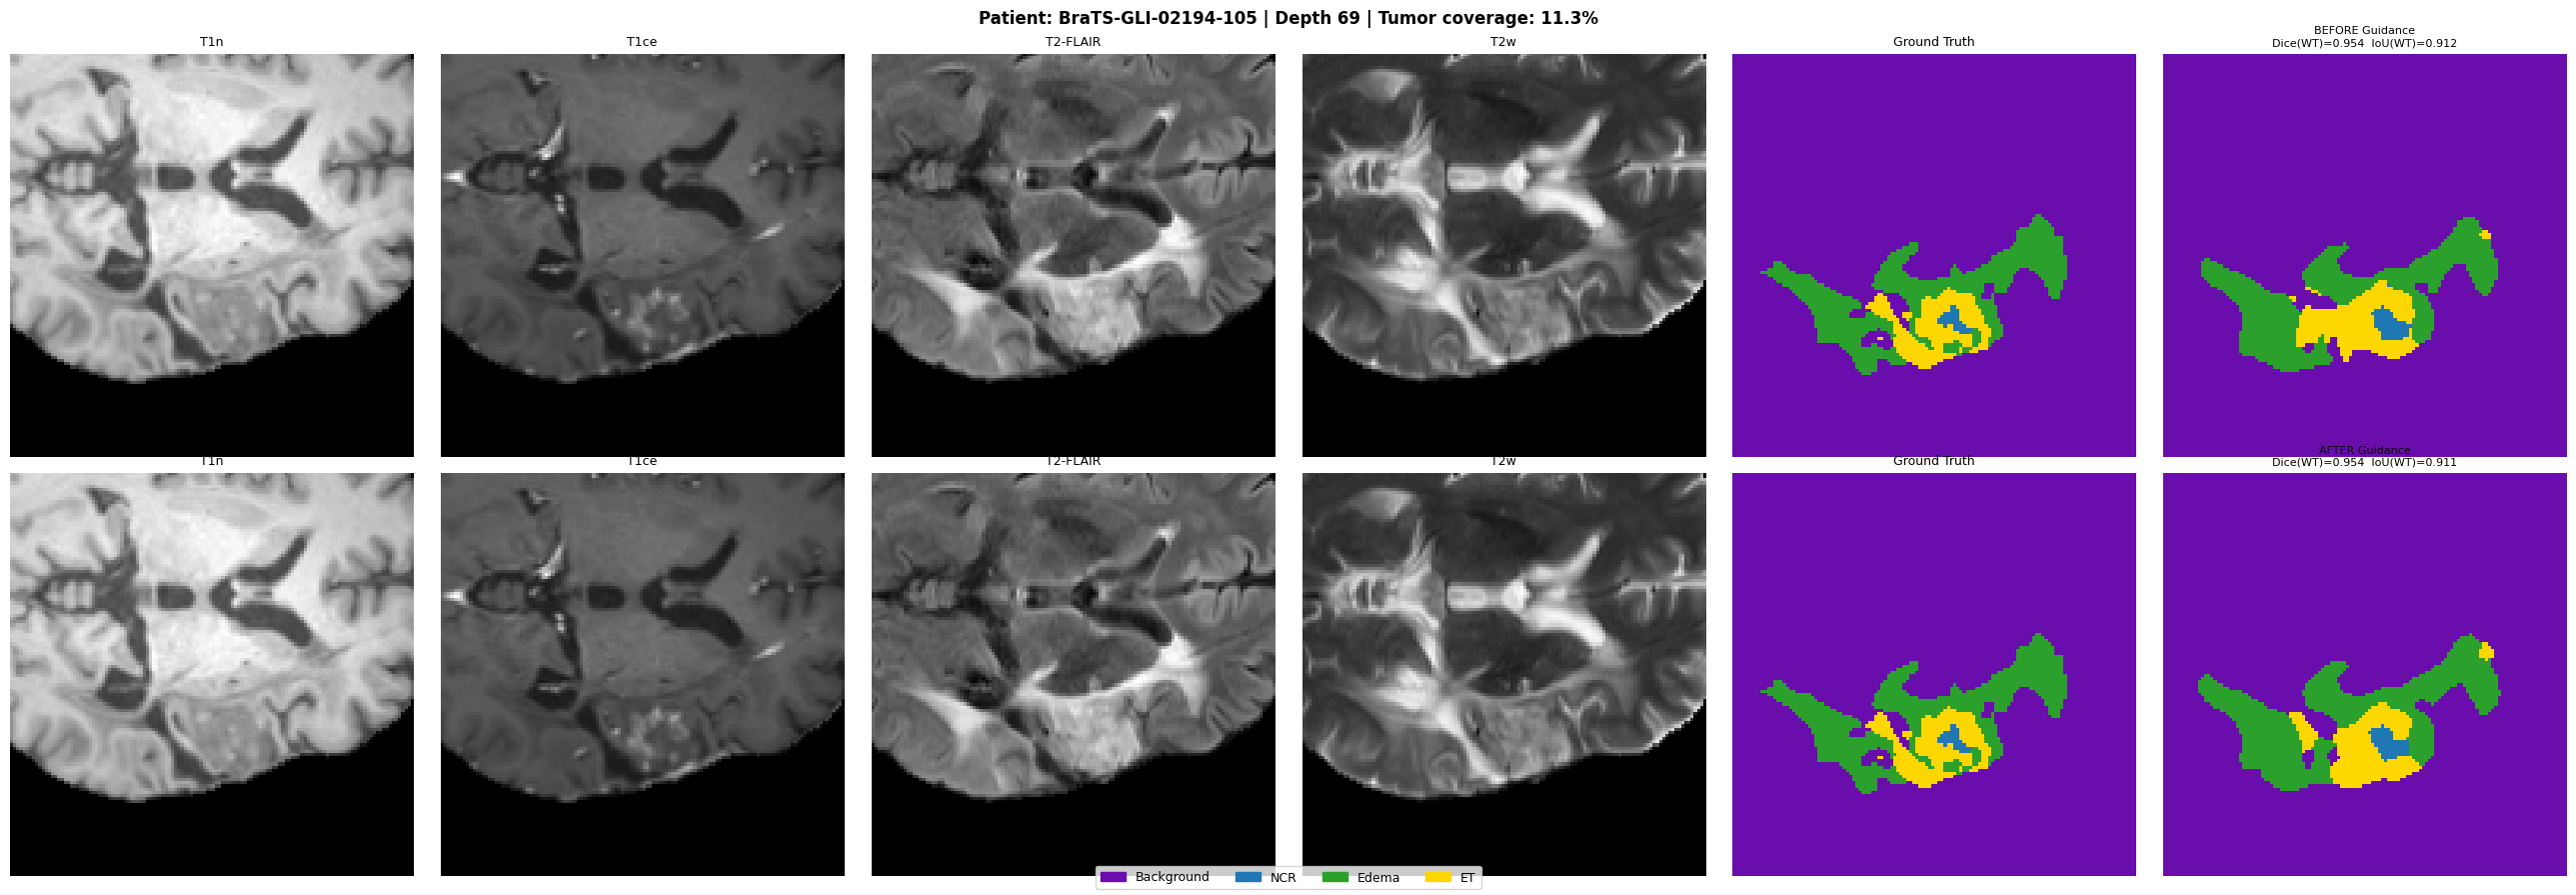

Evaluating C2:  12%|█▎        | 5/40 [00:39<04:26,  7.62s/it]

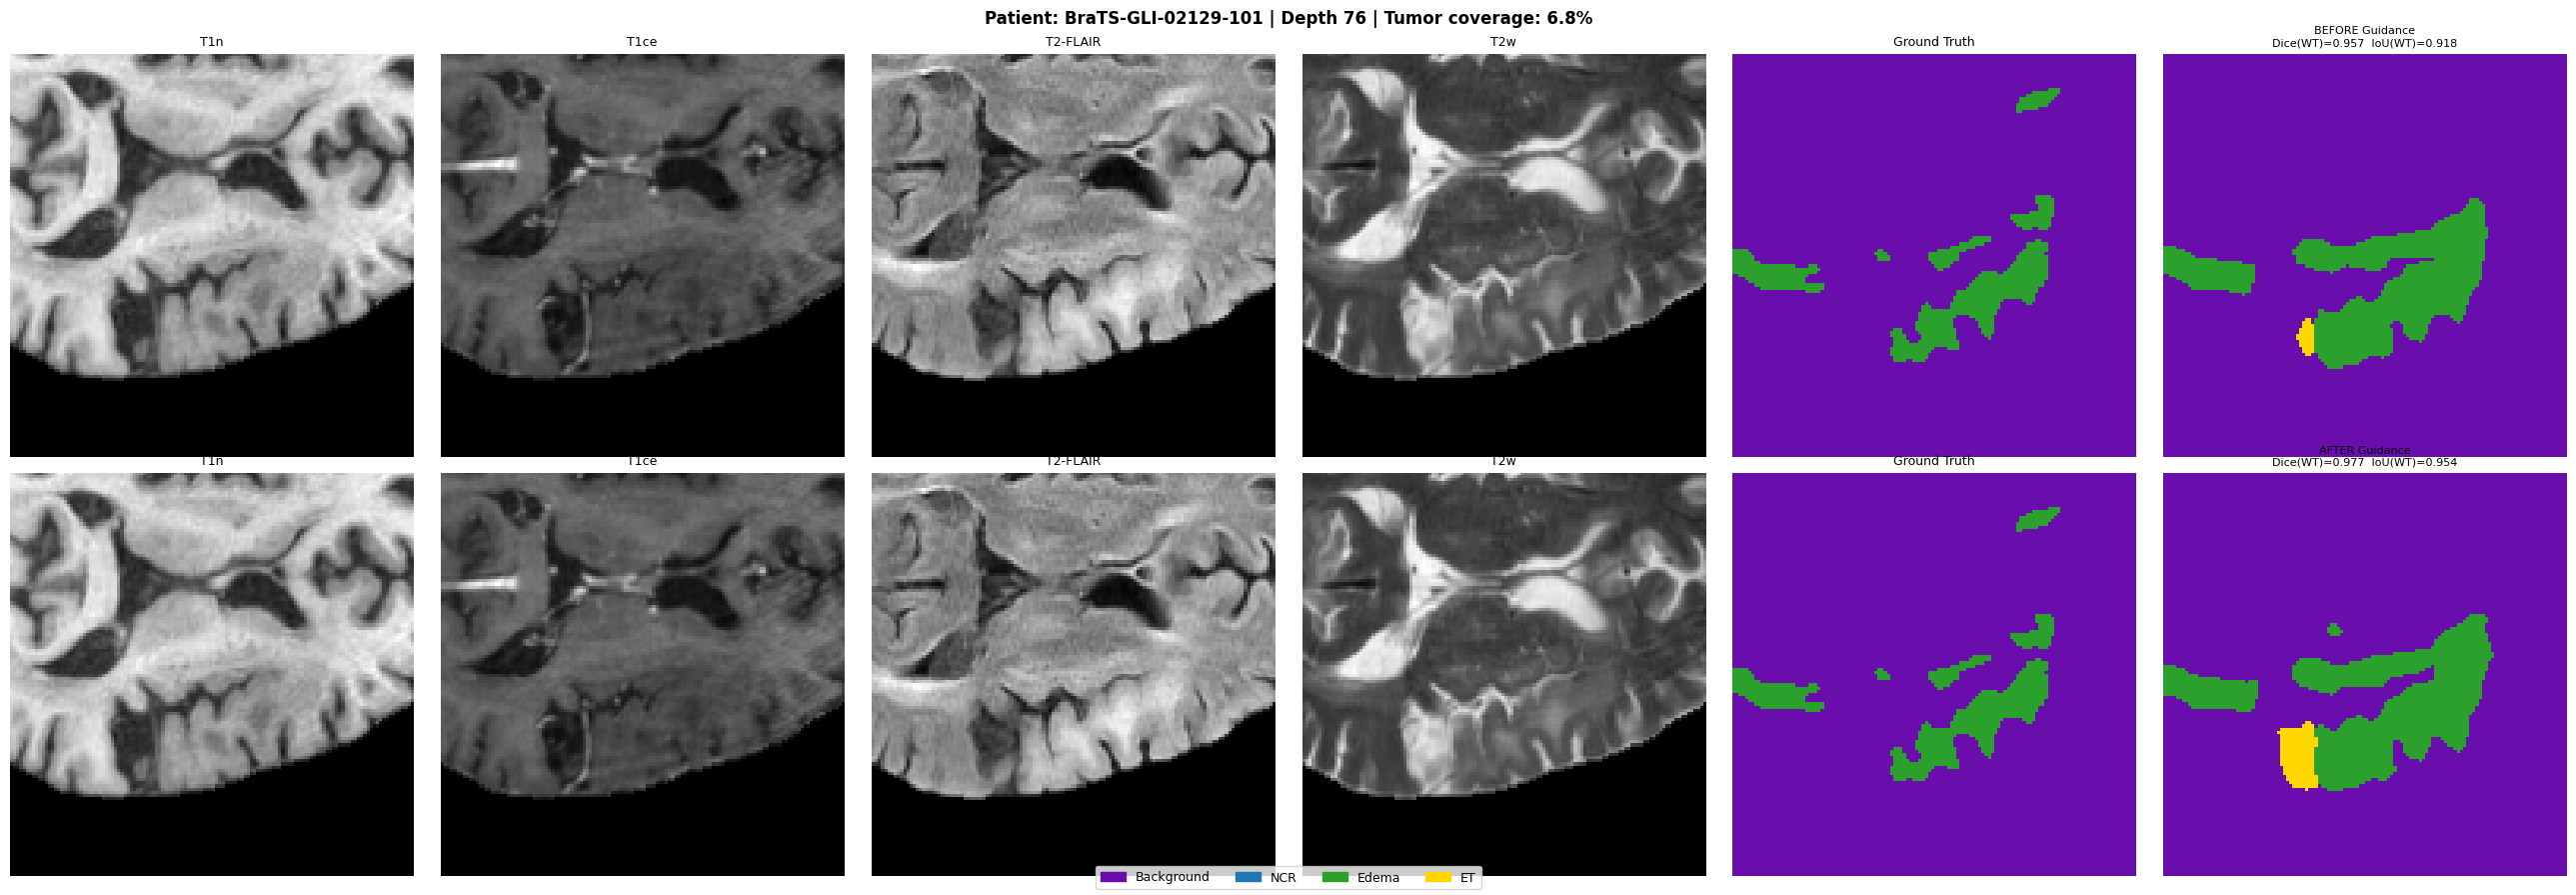

Evaluating C2:  25%|██▌       | 10/40 [01:19<04:01,  8.04s/it]

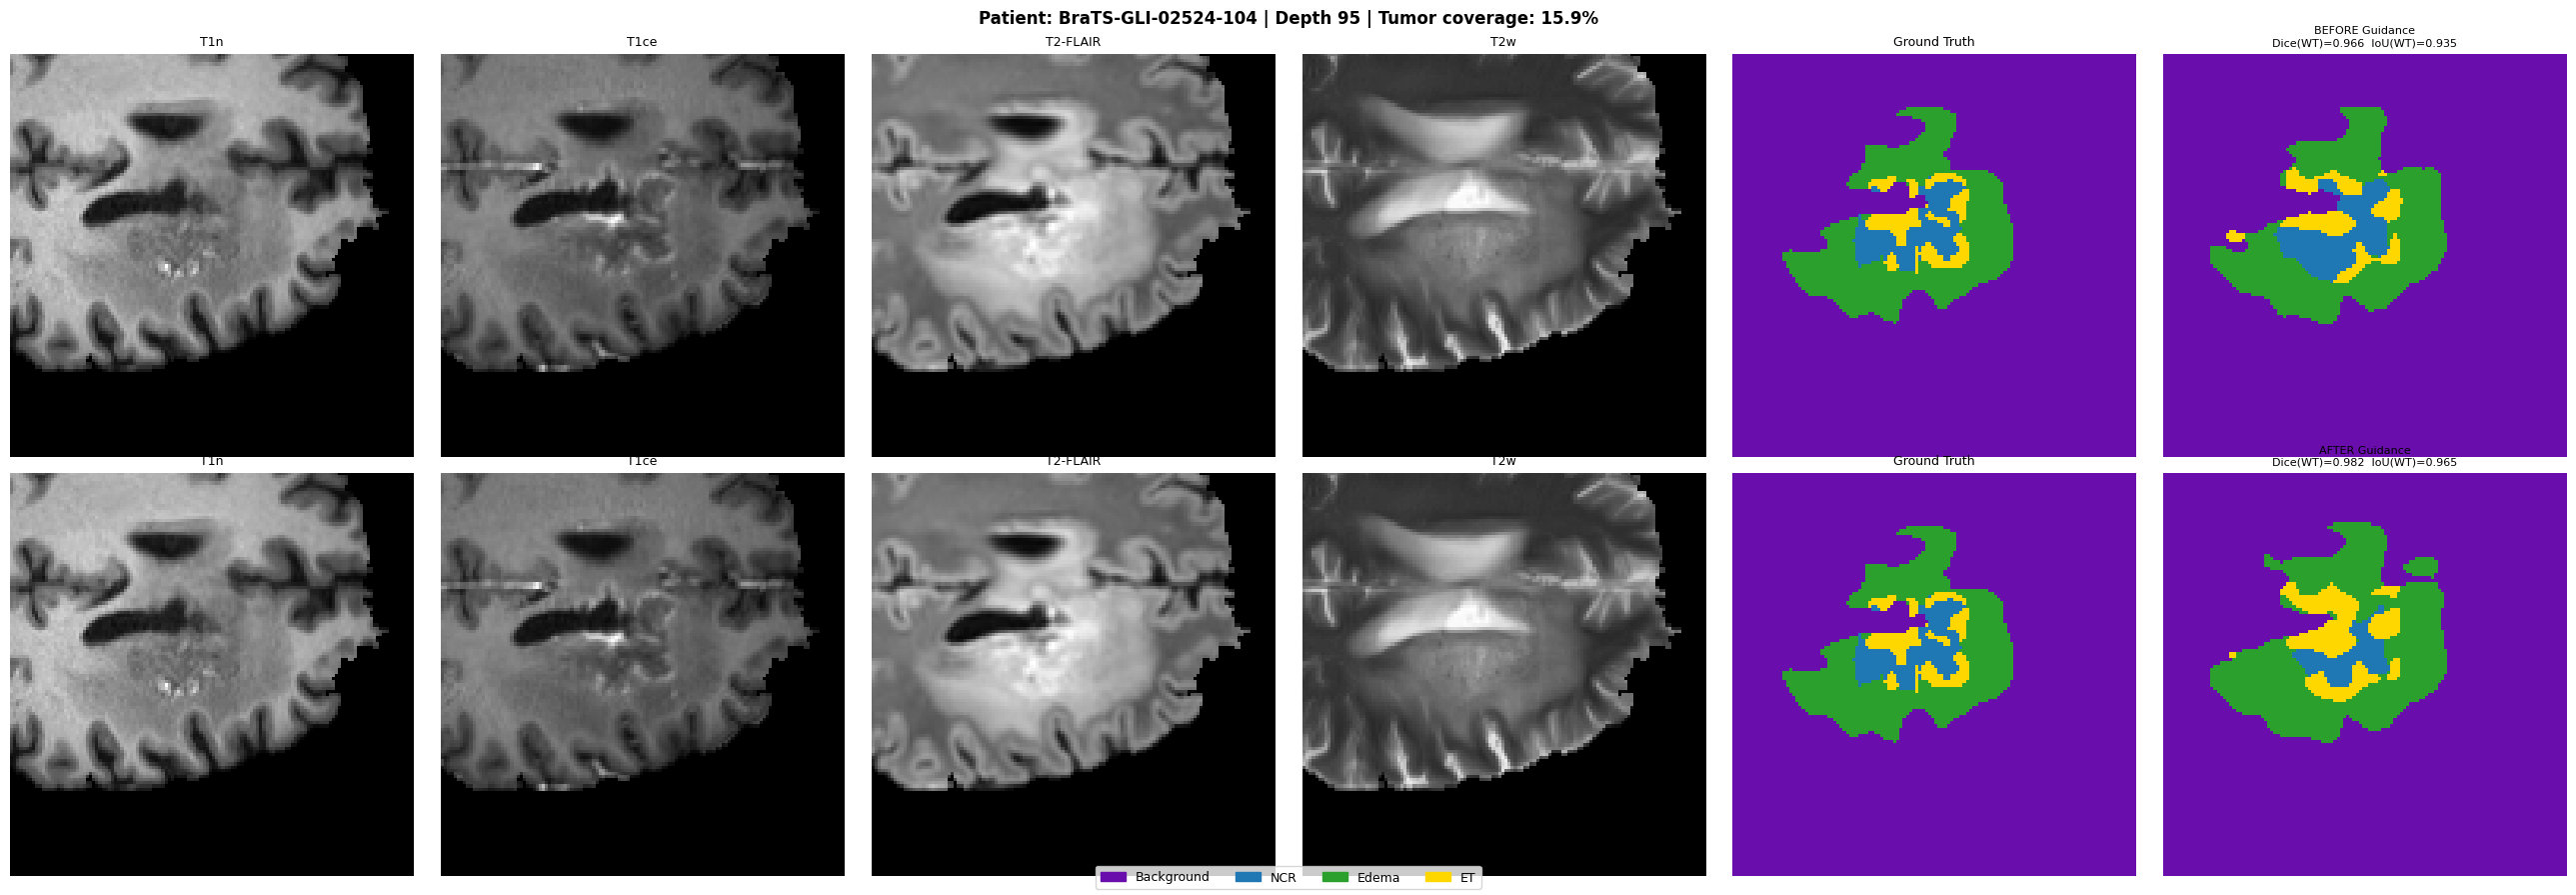

Evaluating C2:  38%|███▊      | 15/40 [01:56<03:03,  7.33s/it]

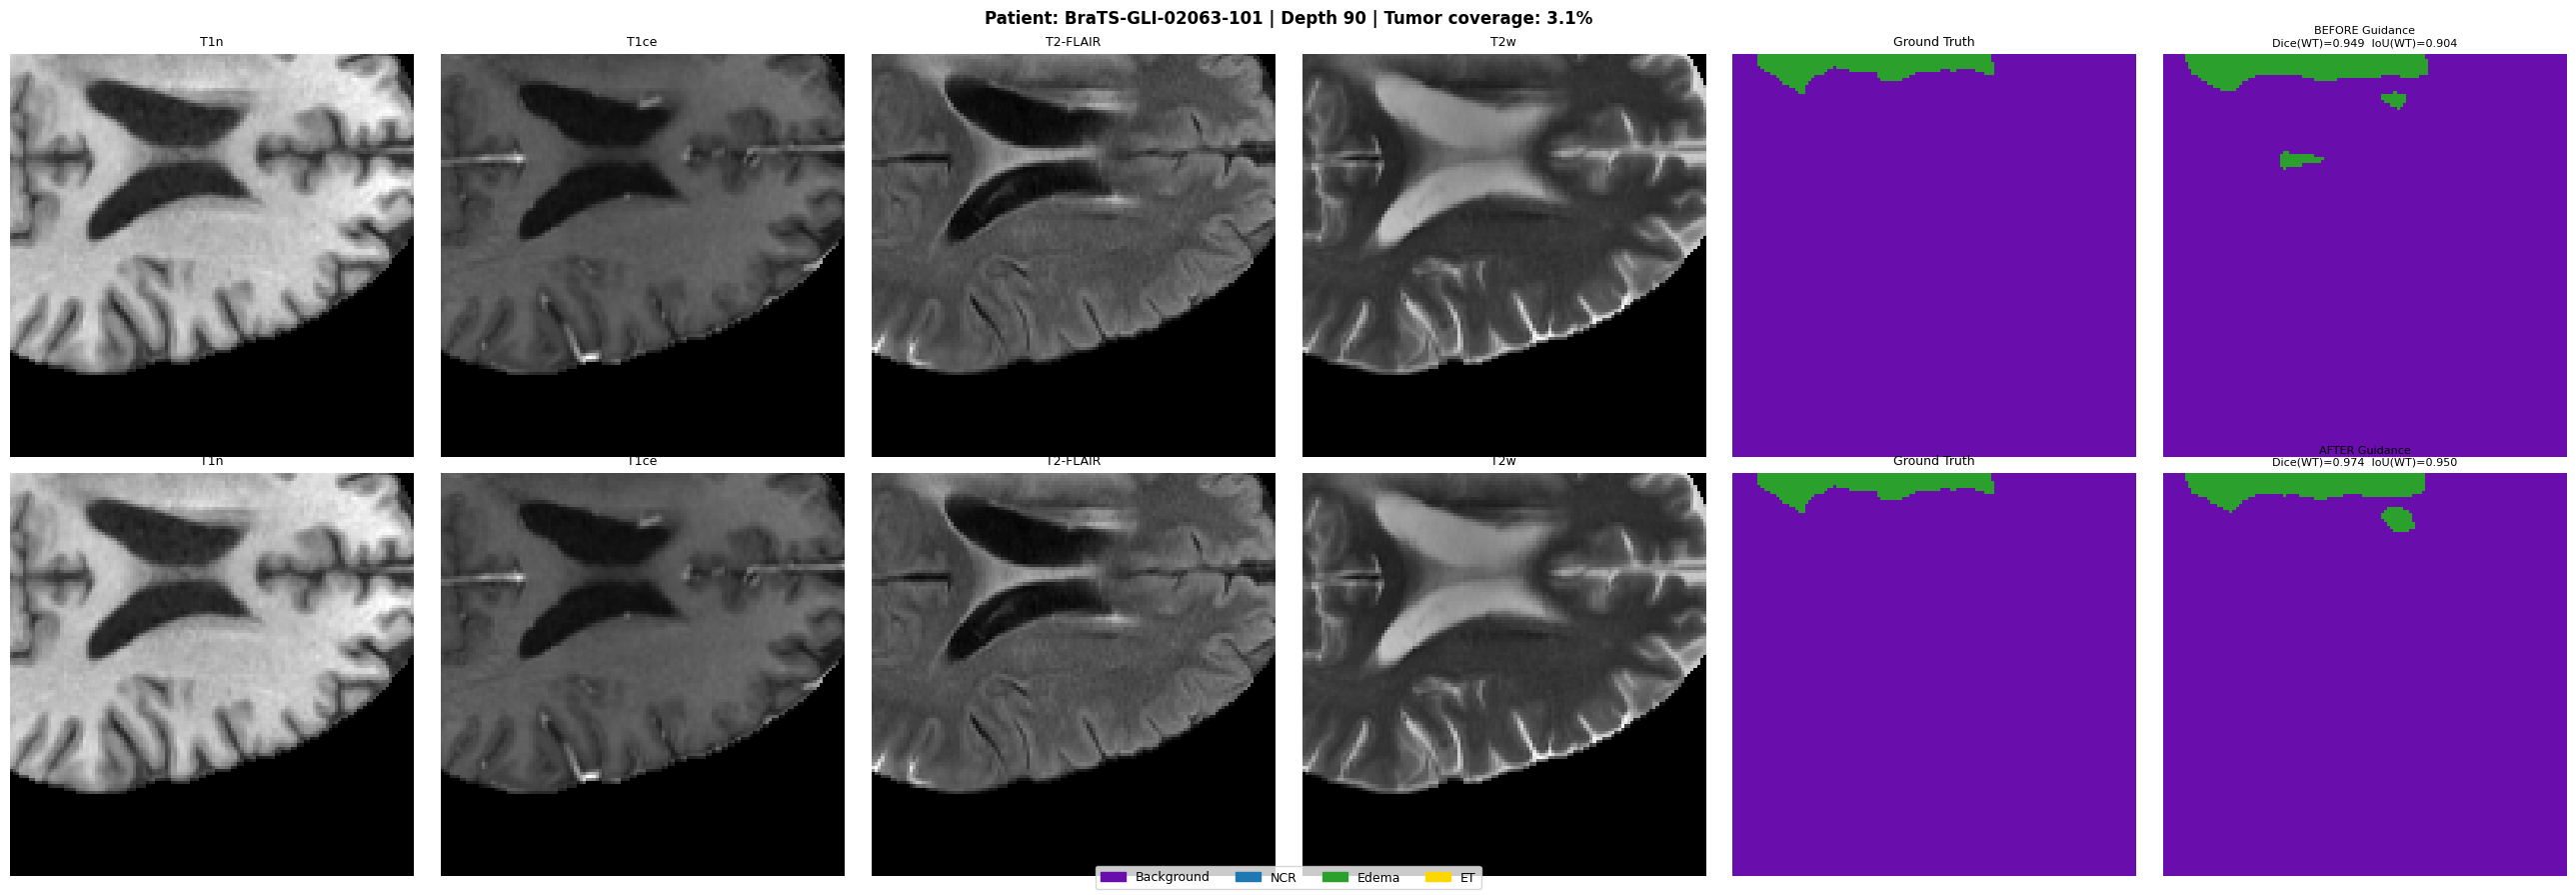

Evaluating C2:  50%|█████     | 20/40 [02:33<02:25,  7.25s/it]

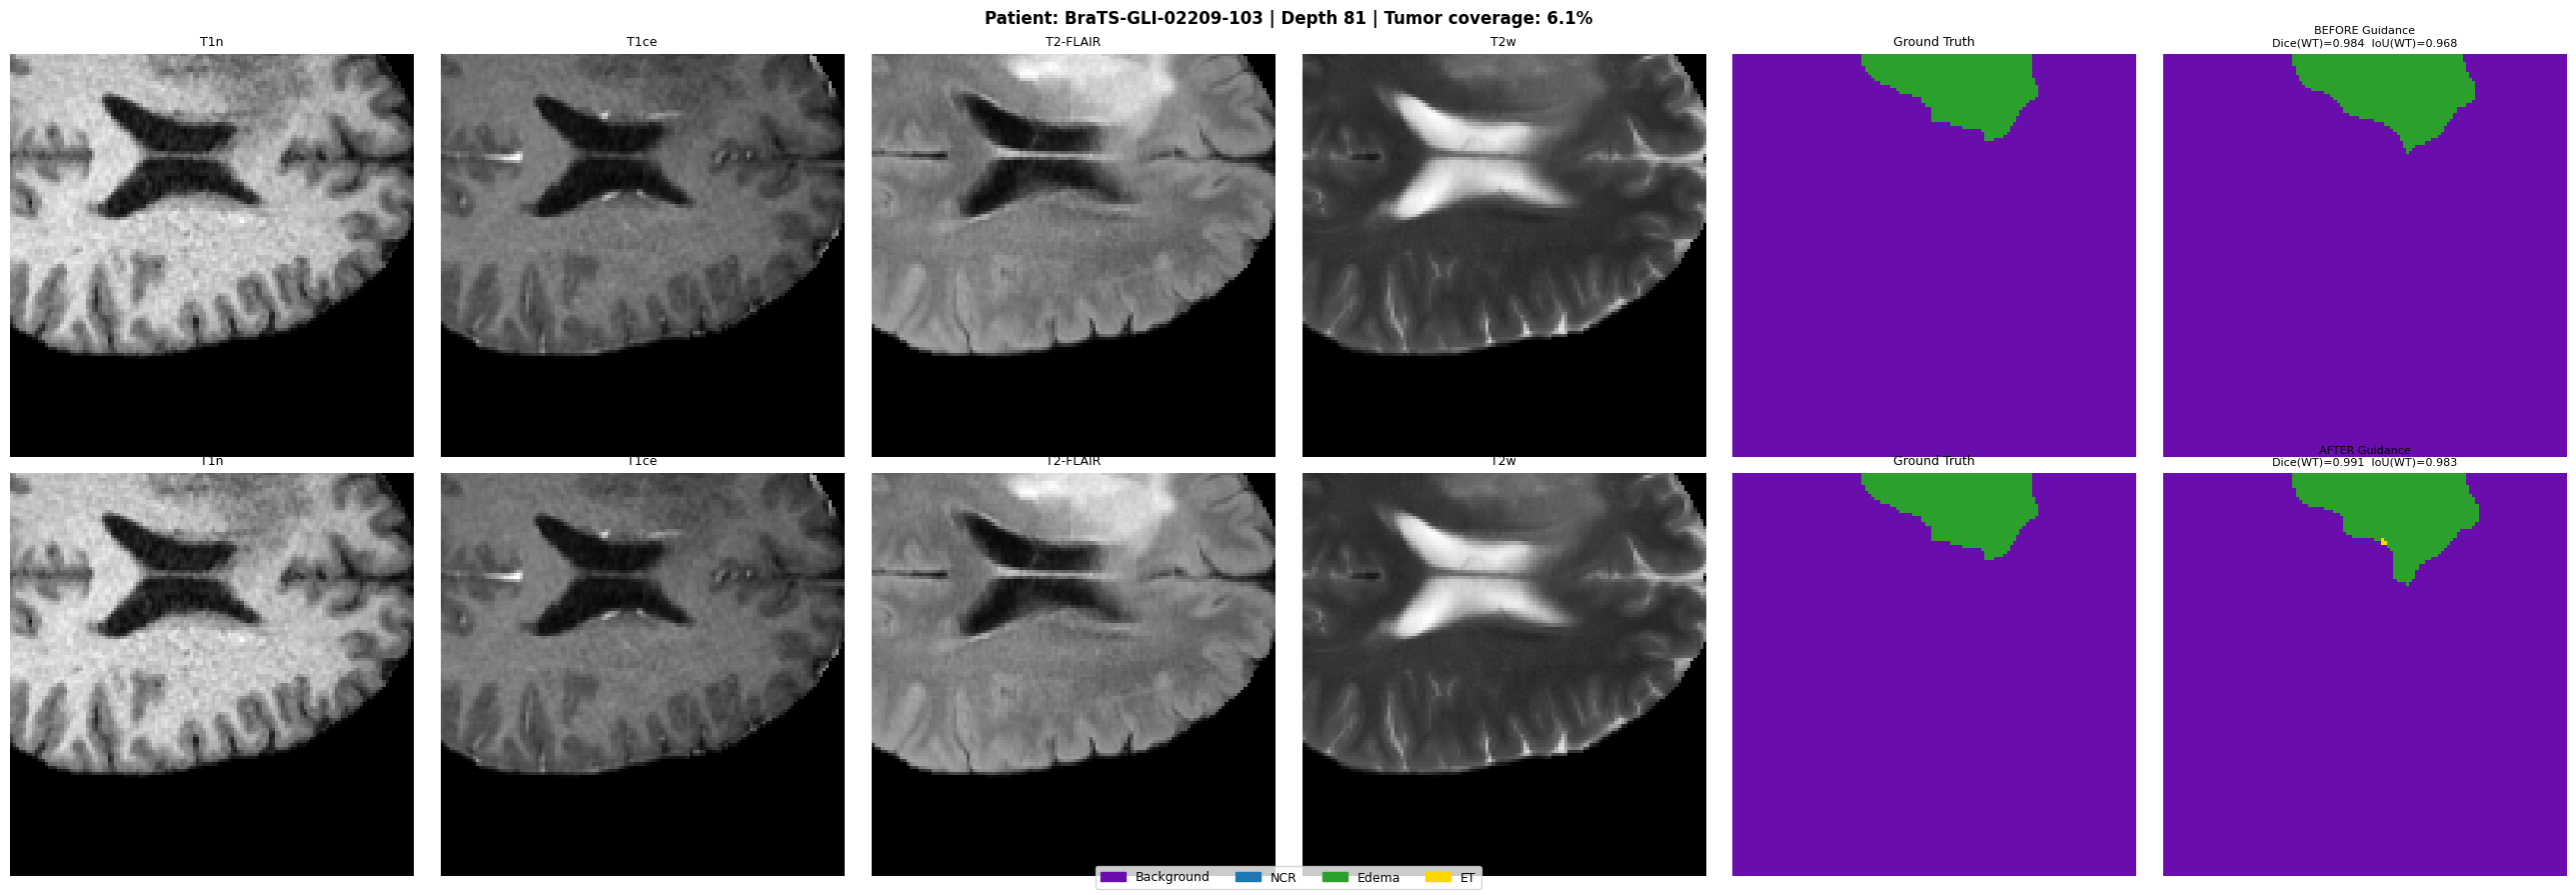

Evaluating C2:  62%|██████▎   | 25/40 [03:10<01:49,  7.31s/it]

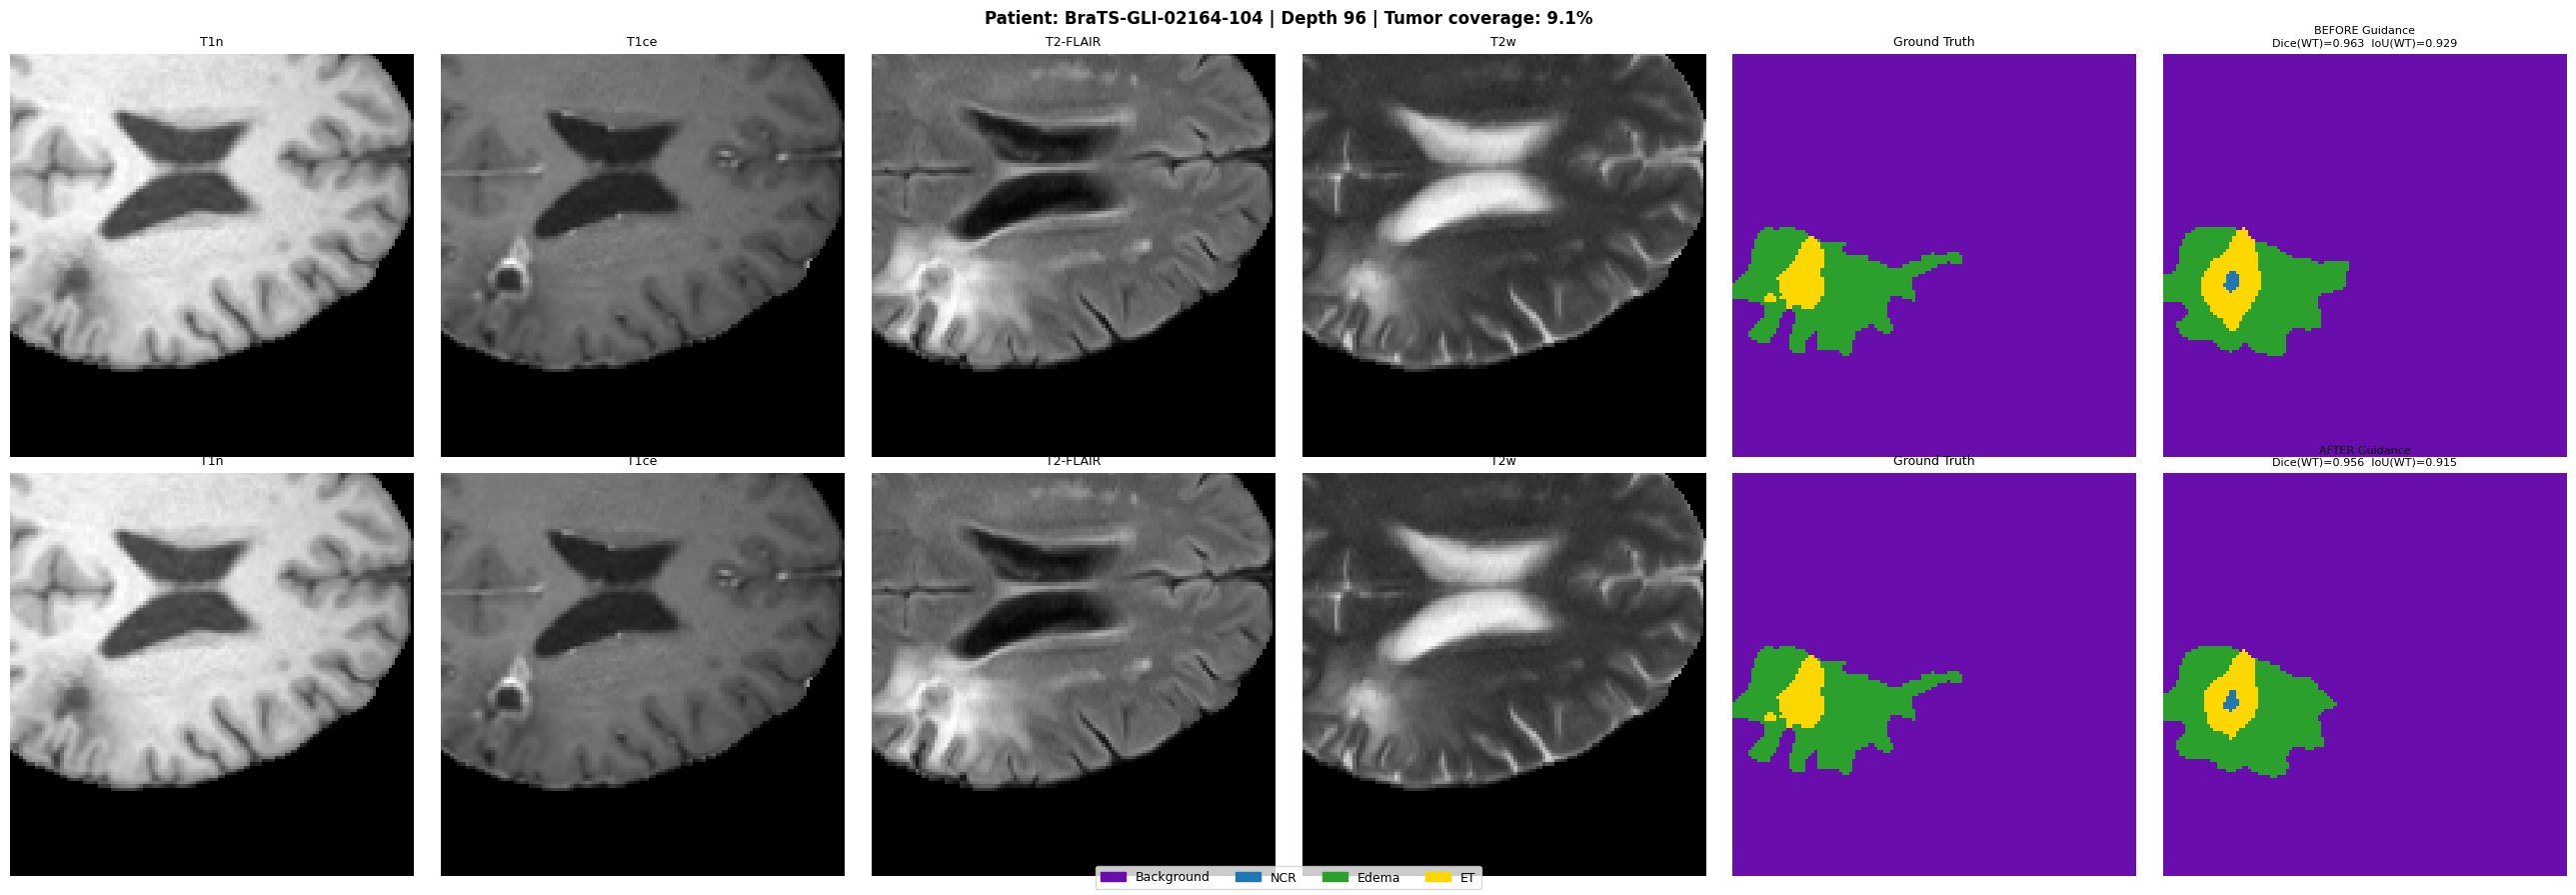

Evaluating C2:  75%|███████▌  | 30/40 [03:47<01:11,  7.12s/it]

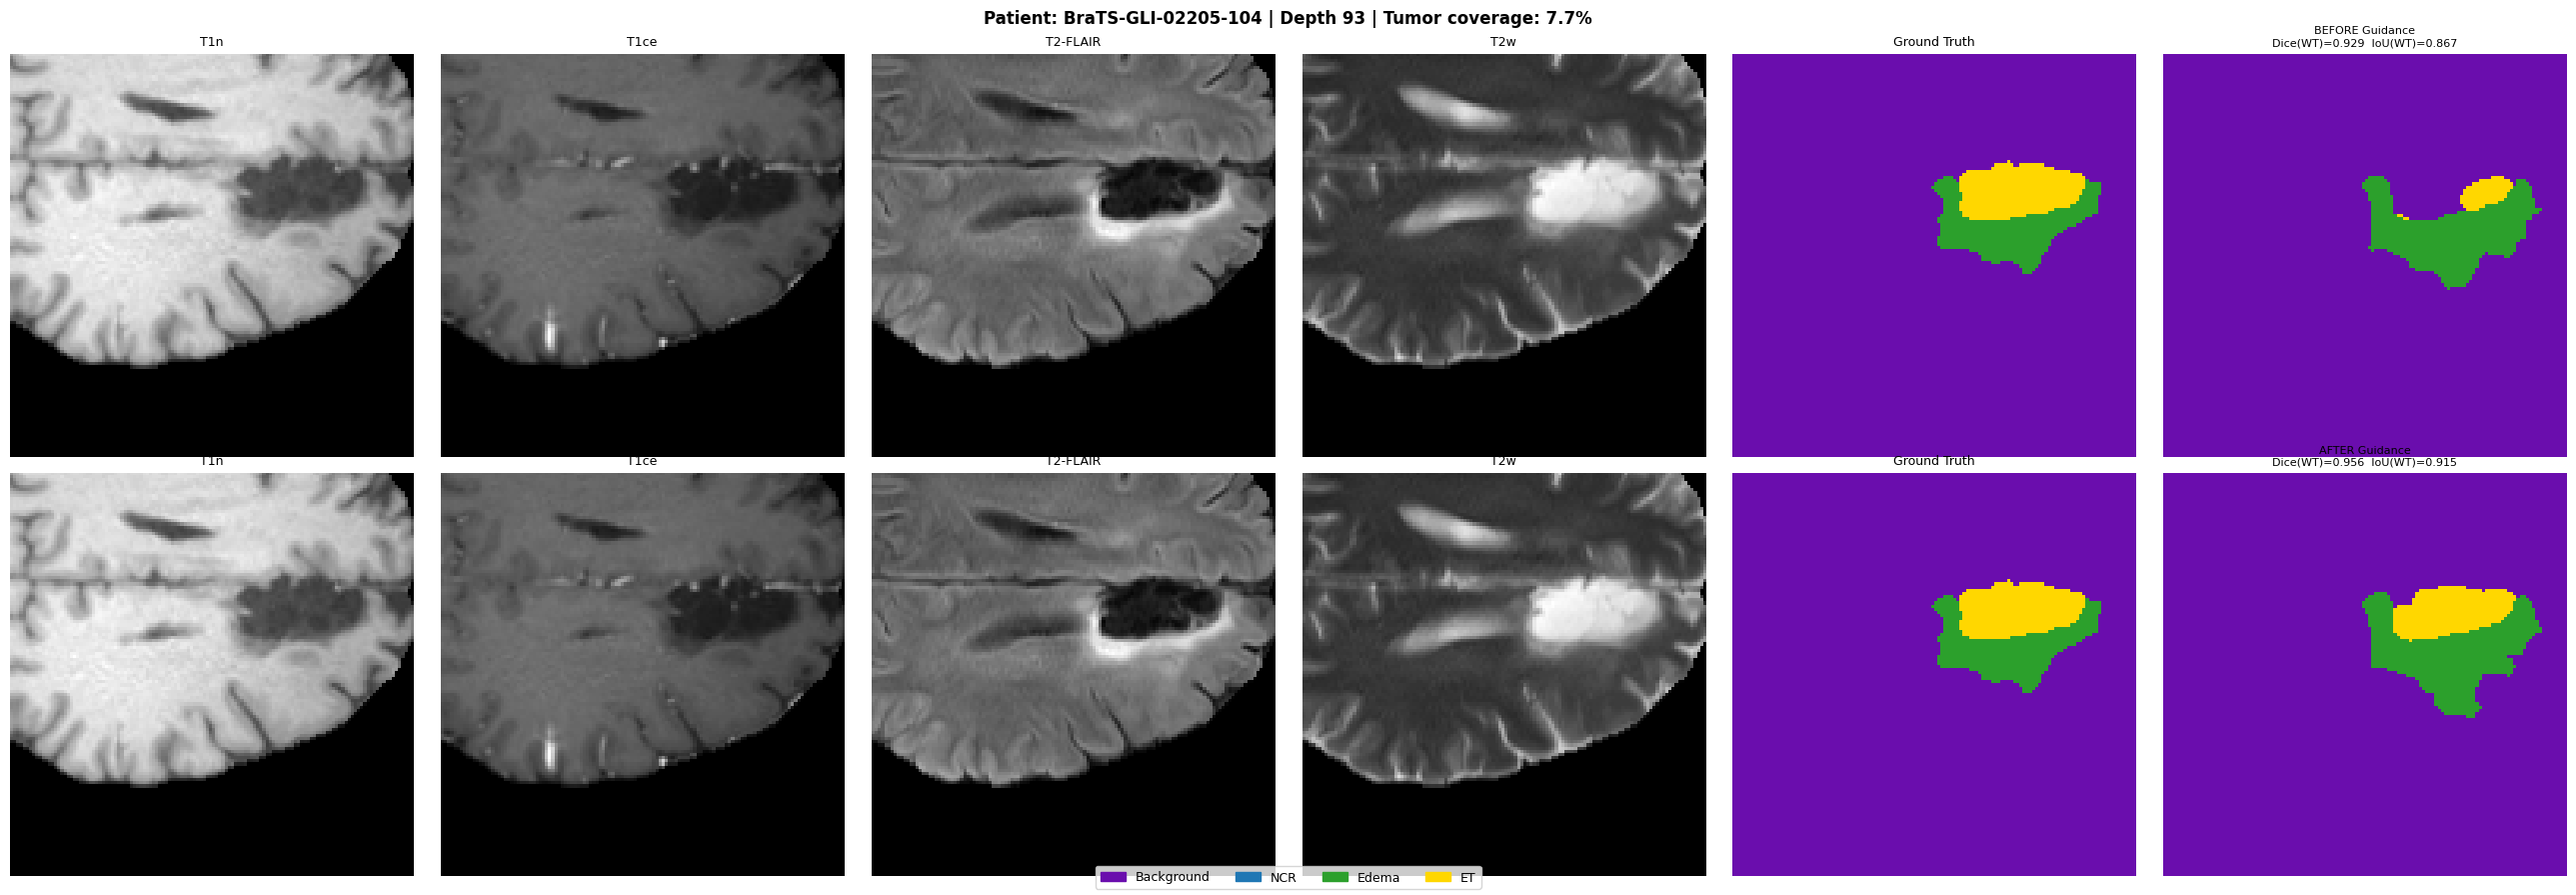

Evaluating C2:  88%|████████▊ | 35/40 [04:24<00:35,  7.19s/it]

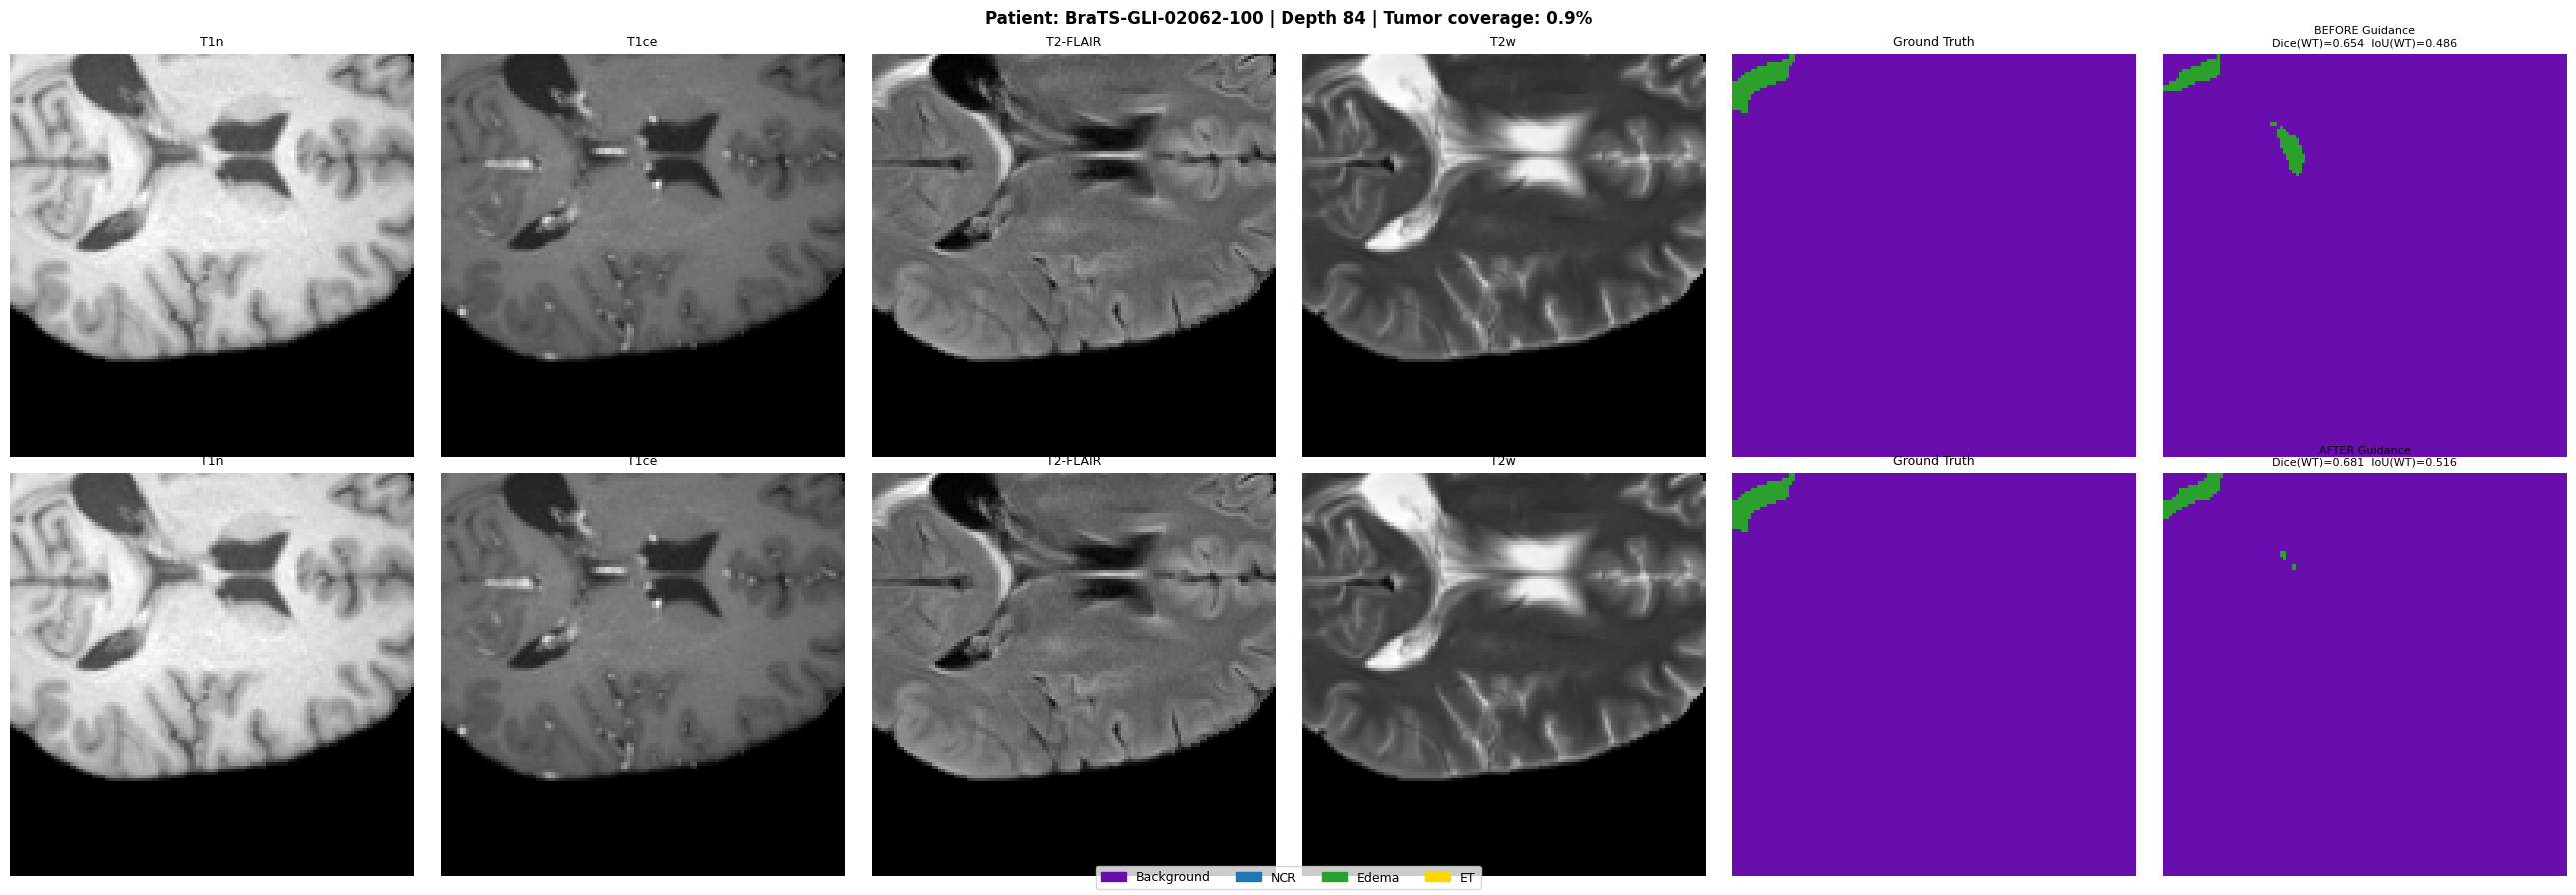

Evaluating C2: 100%|██████████| 40/40 [05:00<00:00,  7.52s/it]


✓ Client 2 evaluation complete — 40 patients


In [ ]:
import os, numpy as np, torch
from tqdm import tqdm
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


# ══════════════════════════════════════════════════════
# PREDICT FUNCTION FOR DEEPLABV3+
# Processes full 3D volume slice by slice, assembles 3D prediction
# ══════════════════════════════════════════════════════
def predict_deeplabv3(model, vol_tensor, guidance_m=None, use_guidance=False):
    """
    vol_tensor: (1, 4, 128, 128, 128) on DEVICE
    Processes each of 128 depth slices independently.
    Returns prediction numpy array (128, 128, 128).
    """
    pred_vol = np.zeros((128, 128, 128), dtype=np.int64)

    with torch.no_grad():
        for z in range(128):
            slc = vol_tensor[0, :, z, :, :].unsqueeze(0)  # (1, 4, 128, 128)

            if use_guidance and guidance_m is not None:
                seg_out, _, _ = model.forward_with_guidance(slc, guidance_m)
            else:
                seg_out, _, _ = model(slc)

            pred_vol[z] = seg_out.argmax(dim=1).cpu().numpy()[0]

    return pred_vol


# ══════════════════════════════════════════════════════
# RUN EVALUATION ON 40 TEST PATIENTS — CLIENT 2
# ══════════════════════════════════════════════════════
all_metrics_before_2 = []
all_metrics_after_2  = []

print(f"Running Client 2 evaluation on {len(test_data)} patients...")
print("=" * 60)

for idx, patient in enumerate(tqdm(test_data, desc="Evaluating C2")):
    pid   = patient['pid']
    image = patient['image']
    gt    = patient['seg']

    vol_t = torch.from_numpy(image).permute(3, 2, 0, 1).float()
    if vol_t.shape[1:] != (128, 128, 128):
        vol_t = F.interpolate(vol_t.unsqueeze(0), size=(128,128,128),
                              mode='trilinear', align_corners=False).squeeze(0)

    mean_v = vol_t.mean(dim=(1,2,3), keepdim=True)
    std_v  = vol_t.std(dim=(1,2,3),  keepdim=True).clamp(min=1e-6)
    vol_t  = ((vol_t - mean_v) / std_v).unsqueeze(0).to(DEVICE)

    gt_t = torch.from_numpy(gt).permute(2, 0, 1).long()
    if gt_t.shape != (128, 128, 128):
        gt_t = F.interpolate(
            gt_t.float().unsqueeze(0).unsqueeze(0),
            size=(128,128,128), mode='nearest'
        ).squeeze().long()
    gt_np = gt_t.numpy()

    # Predict
    pred_before_2 = predict_deeplabv3(dl_before, vol_t,
                                       use_guidance=False)
    pred_after_2  = predict_deeplabv3(dl_after, vol_t,
                                       guidance_m=guidance_mean_2,
                                       use_guidance=True)

    m_before_2 = compute_all_metrics(pred_before_2, gt_np)
    m_after_2  = compute_all_metrics(pred_after_2,  gt_np)

    all_metrics_before_2.append(m_before_2)
    all_metrics_after_2.append(m_after_2)

    # Visualization every 5th patient
    if idx % 5 == 0:
        z = find_best_tumor_slice(gt_np, pred_before_2, pred_after_2)
        imgs_np = vol_t.cpu().numpy()[0]

        fig, axes = plt.subplots(2, 6, figsize=(26, 9))
        fig.suptitle(
            f"Patient: {pid} | Depth {z} | "
            f"Tumor coverage: {(gt_np[z]>0).mean()*100:.1f}%",
            fontsize=12, fontweight='bold'
        )

        for ch, title in enumerate(["T1n", "T1ce", "T2-FLAIR", "T2w"]):
            axes[0, ch].imshow(imgs_np[ch, z], cmap='gray')
            axes[0, ch].set_title(title, fontsize=9)
            axes[0, ch].axis('off')
            axes[1, ch].imshow(imgs_np[ch, z], cmap='gray')
            axes[1, ch].set_title(title, fontsize=9)
            axes[1, ch].axis('off')

        axes[0, 4].imshow(gt_np[z],          cmap=EVAL_CMAP, vmin=0, vmax=3)
        axes[0, 4].set_title("Ground Truth",  fontsize=9)
        axes[0, 4].axis('off')
        axes[0, 5].imshow(pred_before_2[z],   cmap=EVAL_CMAP, vmin=0, vmax=3)
        axes[0, 5].set_title(
            f"BEFORE Guidance\nDice(WT)={m_before_2['WT']['dice']:.3f}  "
            f"IoU(WT)={m_before_2['WT']['iou']:.3f}", fontsize=8)
        axes[0, 5].axis('off')
        axes[0, 0].set_ylabel("BEFORE\nGuidance", fontsize=10,
                               fontweight='bold', color='tomato')

        axes[1, 4].imshow(gt_np[z],         cmap=EVAL_CMAP, vmin=0, vmax=3)
        axes[1, 4].set_title("Ground Truth", fontsize=9)
        axes[1, 4].axis('off')
        axes[1, 5].imshow(pred_after_2[z],   cmap=EVAL_CMAP, vmin=0, vmax=3)
        axes[1, 5].set_title(
            f"AFTER Guidance\nDice(WT)={m_after_2['WT']['dice']:.3f}  "
            f"IoU(WT)={m_after_2['WT']['iou']:.3f}", fontsize=8)
        axes[1, 5].axis('off')
        axes[1, 0].set_ylabel("AFTER\nGuidance", fontsize=10,
                               fontweight='bold', color='steelblue')

        patches = [mpatches.Patch(color=c, label=n)
                   for c, n in zip(CLASS_COLORS, CLASS_NAMES)]
        fig.legend(handles=patches, loc='lower center',
                   ncol=4, fontsize=9, framealpha=0.8)
        plt.tight_layout()
        plt.savefig(
            os.path.join(TEST_RESULTS_DIR, f'eval_deeplab_{pid}_z{z}.png'),
            dpi=120, bbox_inches='tight'
        )
        plt.show()
        plt.close()

    del vol_t
    torch.cuda.empty_cache()

print(f"\n✓ Client 2 evaluation complete — {len(test_data)} patients")

In [ ]:
# ══════════════════════════════════════════════════════
# PRINT CLIENT 2 SUMMARY
# ══════════════════════════════════════════════════════
def aggregate(metrics_list, region, metric):
    values = [m[region][metric] for m in metrics_list]
    return np.mean(values), np.std(values)

print("\n" + "="*80)
print(" DeepLabV3+ EVALUATION RESULTS — 40 HELD-OUT TEST PATIENTS")
print("="*80)
print(f"\n{'Region':<10} {'Metric':<12} {'BEFORE Guidance':>18} "
      f"{'AFTER Guidance':>18} {'Change':>10}")
print("-"*70)

summary_2 = {}
for region in regions:
    for metric in metrics:
        b_mean, b_std = aggregate(all_metrics_before_2, region, metric)
        a_mean, a_std = aggregate(all_metrics_after_2,  region, metric)
        change        = a_mean - b_mean
        arrow         = "↑" if (change > 0 and metric != 'hd95') or \
                                (change < 0 and metric == 'hd95') else "↓"
        print(f"{region:<10} {metric:<12} "
              f"{b_mean:>8.4f}±{b_std:.4f}  "
              f"{a_mean:>8.4f}±{a_std:.4f}  "
              f"{arrow}{abs(change):>8.4f}")
        summary_2[(region, metric)] = (b_mean, b_std, a_mean, a_std)
    print()

# Save
summary_path_2 = os.path.join(TEST_RESULTS_DIR, 'deeplab_evaluation_summary.txt')
with open(summary_path_2, 'w') as f:
    f.write("DeepLabV3+ Evaluation — 40 Held-Out Test Patients\n")
    f.write("="*70 + "\n")
    for region in regions:
        for metric in metrics:
            b_mean, b_std, a_mean, a_std = summary_2[(region, metric)]
            change = a_mean - b_mean
            f.write(f"{region:<10} {metric:<12} "
                    f"{b_mean:>8.4f}±{b_std:.4f}  "
                    f"{a_mean:>8.4f}±{a_std:.4f}  "
                    f"{change:>+8.4f}\n")
        f.write("\n")
print(f"✓ Summary saved → {summary_path_2}")


 DeepLabV3+ EVALUATION RESULTS — 40 HELD-OUT TEST PATIENTS

Region     Metric          BEFORE Guidance     AFTER Guidance     Change
----------------------------------------------------------------------
WT         dice           0.9192±0.0937    0.9386±0.0762  ↑  0.0193
WT         iou            0.8617±0.1300    0.8924±0.1146  ↑  0.0307
WT         sensitivity    0.8617±0.1300    0.8924±0.1146  ↑  0.0307
WT         specificity    1.0000±0.0000    1.0000±0.0000  ↓  0.0000
WT         hd95           2.8752±1.5437    2.3822±1.5573  ↑  0.4930

TC         dice           0.8414±0.2503    0.8712±0.2256  ↑  0.0297
TC         iou            0.7826±0.2658    0.8212±0.2520  ↑  0.0386
TC         sensitivity    0.7826±0.2658    0.8212±0.2520  ↑  0.0386
TC         specificity    1.0000±0.0000    1.0000±0.0000  ↓  0.0000
TC         hd95          10.9971±46.4087   10.5871±46.4767  ↑  0.4099

ET         dice           0.8407±0.2500    0.8706±0.2254  ↑  0.0299
ET         iou            0.7814±0.2655    

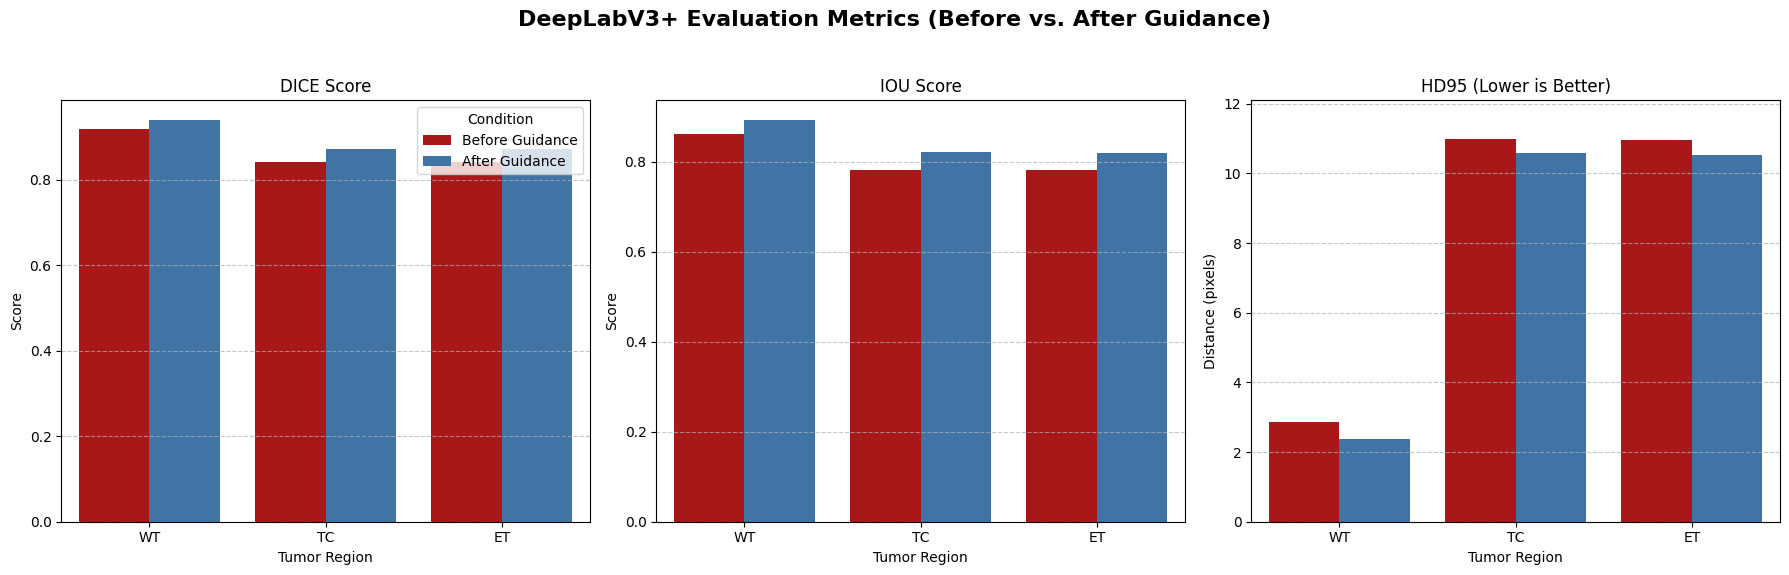


✓ Evaluation metrics plot saved to Drive → /content/drive/MyDrive/BraTS2024_3DUNet/evaluation_results/deeplab_evaluation_metrics_plot.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns # Import seaborn

def create_results_dataframe(summary_dict, regions, metrics):
    data = []
    for region in regions:
        for metric in metrics:
            b_mean, b_std, a_mean, a_std = summary_dict[(region, metric)]
            data.append({
                'Region': region,
                'Metric': metric,
                'Mean (Before)': b_mean,
                'Std (Before)': b_std,
                'Mean (After)': a_mean,
                'Std (After)': a_std
            })
    return pd.DataFrame(data)

# Create a DataFrame from the summary_2 dictionary
df_results = create_results_dataframe(summary_2, regions, metrics)

# Filter for Dice, IoU, and HD95
df_filtered = df_results[df_results['Metric'].isin(['dice', 'iou', 'hd95'])]

# Prepare data for plotting
plot_data = pd.melt(df_filtered, id_vars=['Region', 'Metric'], value_vars=['Mean (Before)', 'Mean (After)'],
                    var_name='Guidance', value_name='Value')
plot_data['Guidance'] = plot_data['Guidance'].replace({'Mean (Before)': 'Before Guidance', 'Mean (After)': 'After Guidance'})

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=False)
fig.suptitle('DeepLabV3+ Evaluation Metrics (Before vs. After Guidance)', fontsize=16, fontweight='bold')

metrics_to_plot = ['dice', 'iou', 'hd95']
y_labels = ['Score', 'Score', 'Distance (pixels)']

for i, metric_name in enumerate(metrics_to_plot):
    ax = axes[i]
    subset = plot_data[plot_data['Metric'] == metric_name]
    sns.barplot(x='Region', y='Value', hue='Guidance', data=subset, palette={'Before Guidance': '#C00000', 'After Guidance': '#2E75B6'}, ax=ax)
    ax.set_title(f'{metric_name.upper()} Score', fontsize=12)
    ax.set_xlabel('Tumor Region', fontsize=10)
    ax.set_ylabel(y_labels[i], fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    if i == 0:
        ax.legend(title='Condition')
    else:
        ax.legend().set_visible(False)

    # Invert y-axis for HD95 to show improvement as moving upwards
    if metric_name == 'hd95':
        min_val = subset['Value'].min() * 0.9 # Small buffer
        max_val = subset['Value'].max() * 1.1 # Small buffer
        ax.set_ylim(top=max_val, bottom=0) # Make sure 0 is always at the bottom
        ax.set_title('HD95 (Lower is Better)', fontsize=12)


plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap

# Save PNG to Drive
PLOT_SAVE_PATH_EVAL = os.path.join(TEST_RESULTS_DIR, 'deeplab_evaluation_metrics_plot.png')
plt.savefig(PLOT_SAVE_PATH_EVAL, dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✓ Evaluation metrics plot saved to Drive → {PLOT_SAVE_PATH_EVAL}")